In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [3]:
from pathlib import Path
from contextlib import ExitStack
import os
import time
import uuid
import rasterio
from affine import Affine
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.windows import Window, from_bounds, bounds
from rasterio.warp import reproject
import numpy as np
import xarray as xr

ERA5_DIR = Path(
    "/exports/geos.ed.ac.uk/gcel/spatial_datasets/"
    "meteorology/ERA5/global_0.1deg"
)
OUTPUT = Path("../../scratch/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc")

VARIABLES = {  # Output name: (input filename prefix, input variable).
    "air_temperature_mean": ("airt_daily_mean", "airt_mean"),
    "air_temperature_min": ("airt_daily_min", "airt_min"),
    "air_temperature_max": ("airt_daily_max", "airt_max"),
    "precipitation_mean": ("precipitation_daily_mean", "daily_precip"),
    "wind_speed_mean": ("wind_spd_daily_mean", "wind_spd"),
    "vpd_mean": ("vpd_daily_mean", "vpd_mean"),
    "sw_radiation_mean": ("sw_radiation_daily_mean", "daily_swrad"),
}

WINTERS = list(range(2018, 2024))
PERIODS = ["OND", "JFM"]

TCC_DIR = Path("../../scratch/climate_site_selection/tcc/")
MIN_CANOPY_COVERAGE = 0.90
MIN_TEMPORAL_COVERAGE = 0.90  # Required separately in every winter-period.
SNOW_DAY_THRESHOLD = 0.1  # kg m-2 day-1; diagnostic threshold, not a selection filter.

# One notebook cell; dependencies: numpy, xarray, dask, netCDF4, rasterio, affine.
# Daily-derived RH and snowfall retain the supplied script's approximations.
# if OUTPUT.exists():
#     raise FileExistsError(f"Choose a new OUTPUT filename; already exists: {OUTPUT}")
tiles = sorted(TCC_DIR.glob("*_tcc_2020.tif"))
if not tiles:
    raise FileNotFoundError(f"No *_tcc_2020.tif files found in {TCC_DIR}")
started = time.perf_counter()
totals = None
minimum_coverage = None
source_attrs = {}
expected_days = 0

for year in range(min(WINTERS), max(WINTERS) + 2):
    print(f"Reading daily fields for {year}", flush=True)
    annual_started = time.perf_counter()

    with ExitStack() as stack:  # Keep this year's input files open during computation.
        daily_fields = {}

        for output_name, (prefix, variable) in VARIABLES.items():
            path = ERA5_DIR / f"{prefix}_{year}.nc"
            ds = stack.enter_context(
                xr.open_dataset(path, chunks={})  # Respect the stored chunk sizes.
            )

            lat = ds["lat"]
            lon = ds["lon"]

            if "long_dim" in lat.dims:
                lat = lat.isel(long_dim=0, drop=True)
            if "lat_dim" in lon.dims:
                lon = lon.isel(lat_dim=0, drop=True)

            lat_attrs = dict(lat.attrs)
            lon_attrs = dict(lon.attrs)

            da = ds[variable]
            extra = [
                d for d in da.dims
                if d not in ("doy", "lat_dim", "long_dim")
            ]
            if extra:
                da = da.squeeze(extra, drop=True)

            da = da.transpose("doy", "lat_dim", "long_dim")

            doy = ds["doy"]
            if np.issubdtype(doy.dtype, np.number):
                origin = 0 if doy.values.min() == 0 else 1
                offsets = doy.values.astype(int) - origin
                dates = (
                    np.datetime64(f"{year}-01-01", "ns")
                    + offsets.astype("timedelta64[D]")
                )
            else:
                dates = doy.values

            daily_fields[output_name] = xr.DataArray(
                da.data,  # Retain lazy loading of the daily data.
                dims=("time", "latitude", "longitude"),
                coords={
                    "time": dates,
                    "latitude": lat.values,
                    "longitude": lon.values,
                },
                attrs={
                    **da.attrs,
                    "source_variable": variable,
                    "source_files": f"{prefix}_YYYY.nc",
                },
            ).sortby("time")

        daily = xr.merge(
            [da.to_dataset(name=name) for name, da in daily_fields.items()],
            join="exact",  # Require matching dates and grids across variables.
        )

        for j, (winter, start, end) in enumerate([
            (year, f"{year}-10-01", f"{year}-12-31"),
            (year - 1, f"{year}-01-01", f"{year}-03-31"),
        ]):
            if winter not in WINTERS:
                continue

            subset = daily.sel(time=slice(start, end)).copy()

            expected = np.arange(np.datetime64(start), np.datetime64(end) + 1,
                                 dtype="datetime64[D]")
            actual = subset.time.values.astype("datetime64[D]")
            if not np.array_equal(actual, expected):
                raise ValueError(f"Missing or duplicate dates in {start} to {end}")
            expected_days += len(expected)

            tmean = subset["air_temperature_mean"] - 273.15  # Kelvin to Celsius.
            tmin = subset["air_temperature_min"] - 273.15
            tmax = subset["air_temperature_max"] - 273.15

            es_min = 610.8 * np.exp(17.27 * tmin / (tmin + 237.3))  # Pa, over water.
            es_max = 610.8 * np.exp(17.27 * tmax / (tmax + 237.3))
            es = (es_min + es_max) / 2  # FAO-56 approximation to daily saturation pressure.
            ea = es - subset["vpd_mean"]  # Estimate daily actual vapour pressure, in Pa.

            subset["relative_humidity_mean"] = (
                100 * ea / es
            ).clip(min=0, max=100)  # Bound the daily RH approximation to 0–100%.

            subset["relative_humidity_mean"].attrs = {
                "long_name": "Estimated daily relative humidity",
                "units": "%",
                "method": (
                    "FAO-56: es = (es(Tmin) + es(Tmax))/2; "
                    "ea = es - VPD; RH = 100*ea/es; bounded to 0–100 percent"
                ),
                "assumption": (
                    "Daily VPD is treated as daily mean saturation pressure "
                    "minus daily mean actual vapour pressure"
                ),
                "limitation": (
                    "Daily saturation pressure and RH are approximations; "
                    "the source VPD processing definition has not been verified"
                ),
                "reference": "Allen et al. (1998), FAO Irrigation and Drainage Paper 56",
            }

            snow_fraction = (
                -0.482292
                * (np.tanh(0.7205 * (tmean - 1.1662)) - 1.0223)
            ).clip(min=0, max=1)  # Dai (2008) annual land coefficients; fraction, not percent.

            snow_fraction = xr.where(
                tmean <= -10, 1.0,
                xr.where(tmean >= 10, 0.0, snow_fraction),
            ).where(tmean.notnull())  # Use all-snow/all-rain limits outside the fitted range.

            precipitation = subset["precipitation_mean"].clip(min=0)
            subset["snowfall_mean"] = precipitation * snow_fraction

            subset["snowfall_mean"].attrs = {
                "long_name": "Estimated daily snowfall water equivalent",
                "units": "kg m-2 day-1",
                "method": (
                    "Daily precipitation multiplied by the Dai (2008) "
                    "temperature-based conditional snow fraction"
                ),
                "snow_fraction_equation": (
                    "clip(-0.482292*(tanh(0.7205*(T_C-1.1662))-1.0223),0,1); "
                    "all snow at T_C <= -10; all rain at T_C >= 10"
                ),
                "limitation": (
                    "Applied to daily mean temperature; does not resolve "
                    "temperature during precipitation or intraday phase changes"
                ),
                "reference": "Dai (2008), doi:10.1029/2008GL033295",
            }

            subset["above_freezing_day_fraction"] = (tmax > 0).where(tmax.notnull())
            subset["freeze_thaw_day_fraction"] = ((tmin < 0) & (tmax > 0)).where(
                tmin.notnull() & tmax.notnull()
            )
            subset["snowfall_day_fraction"] = (
                subset["snowfall_mean"] >= SNOW_DAY_THRESHOLD
            ).where(subset["snowfall_mean"].notnull())
            subset["relative_humidity_clipped_day_fraction"] = (
                ((100 * ea / es) < 0) | ((100 * ea / es) > 100)
            ).where(np.isfinite(ea) & np.isfinite(es))
            for name in list(subset.data_vars):
                subset[name] = subset[name].where(np.isfinite(subset[name]))
            for name in subset.data_vars:
                source_attrs[name] = dict(subset[name].attrs)

            stats = xr.Dataset()
            for name, da in subset.data_vars.items():
                # Centre temperatures before squaring to improve numerical precision.
                offset = 273.15 if name.startswith("air_temperature_") else 0.0
                values = da.astype("float64") - offset
                stats[name + "__sum"] = values.sum("time", skipna=True)
                stats[name + "__count"] = values.count("time")
                if not name.endswith("_fraction"):
                    stats[name + "__sumsq"] = (values * values).sum("time", skipna=True)
            stats = stats.compute(scheduler="single-threaded")
            counts = xr.Dataset({
                name: stats[name + "__count"] / len(expected)
                for name in subset.data_vars
            })
            minimum_coverage = counts if minimum_coverage is None else xr.apply_ufunc(
                np.minimum, minimum_coverage, counts, join="exact"
            )
            if totals is None:
                totals = stats
            else:
                totals, stats = xr.align(totals, stats, join="exact")
                totals = totals + stats
            print(f"  Aggregated {winter}/{str(winter + 1)[-2:]} {PERIODS[j]} "
                  f"({len(expected)} days)", flush=True)
            del subset, stats, counts
    print(f"Finished {year} in {(time.perf_counter() - annual_started)/60:.1f} minutes",
          flush=True)

result = xr.Dataset()
for name, attrs in source_attrs.items():
    count = totals[name + "__count"]
    denominator = count.where(count > 0)
    centered_mean = totals[name + "__sum"] / denominator
    offset = 273.15 if name.startswith("air_temperature_") else 0.0
    result[name] = (centered_mean + offset).astype("float32")
    result[name].attrs = {**attrs, "long_name": name.replace("_", " "),
                          "cell_methods": "time: mean"}
    if name.endswith("_fraction"):
        result[name].attrs["units"] = "1"
    else:
        sd_name = name.removesuffix("_mean") + "_daily_sd"
        variance = (totals[name + "__sumsq"] / denominator - centered_mean**2).clip(min=0)
        result[sd_name] = np.sqrt(variance).astype("float32")
        result[sd_name].attrs = {
            "long_name": f"Population standard deviation of daily {name}",
            "units": attrs.get("units", "unknown"),
            "cell_methods": "time: standard_deviation",
            "description": "Pooled across all selected days, including seasonal and interannual variation",
        }
    result[name + "_valid_day_count"] = count.astype("int32")
    result[name + "_min_period_valid_fraction"] = minimum_coverage[name].astype("float32")
    result[name + "_min_period_valid_fraction"].attrs["units"] = "1"

result["above_freezing_day_fraction"].attrs["definition"] = "Daily Tmax > 0 degrees Celsius"
result["freeze_thaw_day_fraction"].attrs["definition"] = "Daily Tmin < 0 and Tmax > 0 degrees Celsius; air-temperature proxy"
result["snowfall_day_fraction"].attrs["threshold_kg_m2_day"] = SNOW_DAY_THRESHOLD
result["relative_humidity_clipped_day_fraction"].attrs["definition"] = "Fraction of valid days with estimated RH outside 0 to 100 before clipping"
result["latitude"].attrs = {"standard_name": "latitude", "units": "degrees_north"}
result["longitude"].attrs = {"standard_name": "longitude", "units": "degrees_east"}
del totals, minimum_coverage

original_lat = result.latitude.values
original_lon = result.longitude.values
lat_order = np.argsort(original_lat)[::-1]  # Raster calculations require north-to-south rows.
wrapped_lon = (original_lon + 180) % 360 - 180
lon_order = np.argsort(wrapped_lon)  # Also support NetCDF longitudes stored as 0–360.
lat = original_lat[lat_order]
lon = wrapped_lon[lon_order]

dy = float(np.median(-np.diff(lat)))
dx = float(np.median(np.diff(lon)))

if not (
    np.allclose(-np.diff(lat), dy)
    and np.allclose(np.diff(lon), dx)
    and dx > 0 and dy > 0
):
    raise ValueError("Expected a regular latitude/longitude grid without duplicate longitudes")

west, east = float(lon[0] - dx / 2), float(lon[-1] + dx / 2)
south, north = float(lat[-1] - dy / 2), float(lat[0] + dy / 2)
transform = from_origin(west, north, dx, dy)

shape = (len(lat), len(lon))
weighted = np.zeros(shape, dtype="float64")
covered = np.zeros(shape, dtype="float64")
used = 0

for path in tiles:
    with rasterio.open(path) as src:
        if src.crs is None or src.crs.to_epsg() != 4326 or src.count != 1:
            raise ValueError(f"Expected a one-band EPSG:4326 canopy tile: {path}")

        left = max(west, src.bounds.left)
        right = min(east, src.bounds.right)
        bottom = max(south, src.bounds.bottom)
        top = min(north, src.bounds.top)

        if left >= right or bottom >= top:
            continue

        used += 1
        raw = from_bounds(left, bottom, right, top, transform=src.transform)
        col0 = max(0, int(np.floor(raw.col_off)))
        row0 = max(0, int(np.floor(raw.row_off)))
        col1 = min(src.width, int(np.ceil(raw.col_off + raw.width)))
        row1 = min(src.height, int(np.ceil(raw.row_off + raw.height)))

        pad_x = int(np.ceil(dx / abs(src.res[0]))) + 2
        pad_y = int(np.ceil(dy / abs(src.res[1]))) + 2

        for row in range(row0, row1, 4096):
            for col in range(col0, col1, 4096):
                window = Window(
                    col, row,
                    min(4096, col1 - col),
                    min(4096, row1 - row),
                )
                values = src.read(1, window=window, masked=True)
                data = values.astype("float32").filled(255)
                valid = (
                    ~np.ma.getmaskarray(values)
                    & np.isfinite(data)
                    & (data >= 0)
                    & (data <= 100)
                )
                if not valid.any():
                    continue

                # Restrict each warp to the small part of the NetCDF grid it touches.
                block_left, block_bottom, block_right, block_top = bounds(
                    window, src.transform
                )
                target = from_bounds(
                    block_left, block_bottom, block_right, block_top,
                    transform=transform,
                )
                r0 = max(0, int(np.floor(target.row_off)))
                c0 = max(0, int(np.floor(target.col_off)))
                r1 = min(len(lat), int(np.ceil(target.row_off + target.height)))
                c1 = min(len(lon), int(np.ceil(target.col_off + target.width)))

                if r0 >= r1 or c0 >= c1:
                    continue

                # Padding ensures partial contributions at source-block edges are retained.
                source_transform = (
                    src.window_transform(window)
                    * Affine.translation(-pad_x, -pad_y)
                )
                data = np.pad(
                    np.where(valid, data, 255),
                    ((pad_y, pad_y), (pad_x, pad_x)),
                    constant_values=255,
                )
                mask = np.pad(
                    valid.astype("float32"),
                    ((pad_y, pad_y), (pad_x, pad_x)),
                )

                block_shape = (r1 - r0, c1 - c0)
                destination_transform = transform * Affine.translation(c0, r0)
                mean = np.full(block_shape, np.nan, dtype="float32")
                fraction = np.zeros(block_shape, dtype="float32")

                reproject(
                    data, mean,
                    src_transform=source_transform,
                    src_crs=src.crs,
                    src_nodata=255,
                    dst_transform=destination_transform,
                    dst_crs="EPSG:4326",
                    dst_nodata=np.nan,
                    resampling=Resampling.average,
                )
                reproject(
                    mask, fraction,
                    src_transform=source_transform,
                    src_crs=src.crs,
                    dst_transform=destination_transform,
                    dst_crs="EPSG:4326",
                    dst_nodata=0,
                    resampling=Resampling.average,
                )  # Zero mask values must participate in the coverage average.

                fraction = np.clip(fraction, 0, 1)
                weighted[r0:r1, c0:c1] += np.nan_to_num(mean) * fraction
                covered[r0:r1, c0:c1] += fraction

    print(f"Aggregated {path.name}", flush=True)

if used == 0:
    raise ValueError("None of the cached canopy tiles overlaps the NetCDF grid")

canopy = np.full(shape, np.nan, dtype="float32")
np.divide(weighted, covered, out=canopy, where=covered > 0)
if np.any(covered > 1.01):
    raise ValueError("Canopy coverage exceeds 1: check for overlapping or duplicate tiles")
coverage = np.clip(covered, 0, 1).astype("float32")

restore_lat = np.argsort(lat_order)  # Restore the NetCDF's original coordinate ordering.
restore_lon = np.argsort(lon_order)
canopy = canopy[np.ix_(restore_lat, restore_lon)]
coverage = coverage[np.ix_(restore_lat, restore_lon)]

result["tree_canopy_cover_2020"] = (("latitude", "longitude"), canopy)
result["tree_canopy_coverage_fraction"] = (("latitude", "longitude"), coverage)
result["tree_canopy_cover_2020"].attrs = {
    "units": "%", "long_name": "Mean valid NASA ABoVE tree canopy cover, 2020",
    "source": "NASA ABoVE, doi:10.3334/ORNLDAAC/2012",
    "aggregation": "Valid-pixel mean with angular grid-cell overlap weights",
}
result["tree_canopy_coverage_fraction"].attrs = {
    "units": "1", "long_name": "Approximate valid canopy fraction of grid cell"
}
core = ["air_temperature_mean", "snowfall_mean", "relative_humidity_mean", "wind_speed_mean"]
eligible = (result.tree_canopy_coverage_fraction >= MIN_CANOPY_COVERAGE)
eligible &= np.isfinite(result.tree_canopy_cover_2020) & (result.tree_canopy_cover_2020 > 0)
for name in core:
    eligible &= np.isfinite(result[name])
    eligible &= result[name + "_min_period_valid_fraction"] >= MIN_TEMPORAL_COVERAGE
result["eligible_cell"] = eligible.astype("int8")
result["eligible_cell"].attrs = {
    "long_name": "Candidate cell for later study-area screening",
    "minimum_canopy_coverage": MIN_CANOPY_COVERAGE,
    "minimum_valid_fraction_each_winter_period": MIN_TEMPORAL_COVERAGE,
    "description": "Nonzero canopy and valid climate; no minimum snowfall imposed",
}
cc = result.tree_canopy_cover_2020
band = xr.where((cc > 0) & (cc < 25), 1,
                xr.where((cc >= 25) & (cc <= 50), 2, xr.where(cc > 50, 3, 0)))
result["canopy_band"] = band.astype("int8")
result["canopy_band"].attrs = {
    "flag_values": np.array([0, 1, 2, 3], dtype="int8"),
    "flag_meanings": "zero_or_missing low moderate high",
    "description": "Low: 0 < cover < 25%; moderate: 25 <= cover <= 50%; high: >50%. Apply eligible_cell separately.",
}
result.attrs = {
    "title": "Climate and canopy maps for study-area selection",
    "winters": ", ".join(f"{y}/{y+1}" for y in WINTERS),
    "periods": "OND and JFM (October to March)",
    "expected_daily_records": expected_days,
    "aggregation": "Equal weight per valid day across all selected winters and periods; all map variables are two-dimensional",
    "variability": "Daily population SD; includes within-period, between-period and between-year variability",
    "source_directory": str(ERA5_DIR), "canopy_directory": str(TCC_DIR),
    "humidity_caveat": "Estimated from daily VPD and Tmin/Tmax; source VPD definition unverified",
    "snowfall_caveat": "Estimated from daily precipitation and mean air temperature, not directly from ERA5 snowfall",
}
encoding = {}
for name, da in result.data_vars.items():
    encoding[name] = {"zlib": True, "complevel": 4,
                      "chunksizes": (min(180, result.sizes["latitude"]),
                                     min(360, result.sizes["longitude"]))}
    if np.issubdtype(da.dtype, np.floating):
        encoding[name]["dtype"] = "float32"

OUTPUT.parent.mkdir(parents=True, exist_ok=True)
temporary = OUTPUT.with_name(OUTPUT.stem + "." + uuid.uuid4().hex + ".partial.nc")
try:
    result.to_netcdf(temporary, engine="netcdf4", encoding=encoding)
    # Same-directory hard link publishes the complete file without replacing an existing file.
    os.replace(temporary, OUTPUT)
finally:
    temporary.unlink(missing_ok=True)

print(result)
print(f"Saved: {OUTPUT.resolve()}")
print(f"Eligible cells: {int(result.eligible_cell.sum()):,}")
print(f"Elapsed: {(time.perf_counter() - started)/60:.1f} minutes")


Reading daily fields for 2018
  Aggregated 2018/19 OND (92 days)
Finished 2018 in 4.3 minutes
Reading daily fields for 2019
  Aggregated 2019/20 OND (92 days)
  Aggregated 2018/19 JFM (90 days)
Finished 2019 in 7.8 minutes
Reading daily fields for 2020
  Aggregated 2020/21 OND (92 days)
  Aggregated 2019/20 JFM (91 days)
Finished 2020 in 7.7 minutes
Reading daily fields for 2021
  Aggregated 2021/22 OND (92 days)
  Aggregated 2020/21 JFM (90 days)
Finished 2021 in 7.7 minutes
Reading daily fields for 2022
  Aggregated 2022/23 OND (92 days)
  Aggregated 2021/22 JFM (90 days)
Finished 2022 in 7.7 minutes
Reading daily fields for 2023
  Aggregated 2023/24 OND (92 days)
  Aggregated 2022/23 JFM (90 days)
Finished 2023 in 7.7 minutes
Reading daily fields for 2024
  Aggregated 2023/24 JFM (91 days)
Finished 2024 in 3.7 minutes
Aggregated 005E_60N_tcc_2020.tif
Aggregated 008E_60N_tcc_2020.tif
Aggregated 008E_62N_tcc_2020.tif
Aggregated 008E_65N_tcc_2020.tif
Aggregated 010E_60N_tcc_2020.tif
Ag

In [4]:
from pathlib import Path
import os
import time
import numpy as np
import pandas as pd
import xarray as xr

LUKE_DIR = Path(
    "../../scratch/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc"
)

ds = xr.open_dataset(LUKE_DIR)
ds

<xarray.Dataset> Size: 1GB
Dimensions:                                                           (
                                                                       latitude: 1800,
                                                                       longitude: 3600)
Coordinates:
  * latitude                                                          (latitude) float64 14kB ...
  * longitude                                                         (longitude) float64 29kB ...
Data variables: (12/52)
    air_temperature_mean                                              (latitude, longitude) float32 26MB ...
    air_temperature_daily_sd                                          (latitude, longitude) float32 26MB ...
    air_temperature_mean_valid_day_count                              (latitude, longitude) int32 26MB ...
    air_temperature_mean_min_period_valid_fraction                    (latitude, longitude) float32 26MB ...
    air_temperature_min                                               (latitude, longitude) float32 26MB ...
    air_temperature_min_daily_sd                                      (latitude, longitude) float32 26MB ...
    ...                                                                ...
    relative_humidity_clipped_day_fraction_valid_day_count            (latitude, longitude) int32 26MB ...
    relative_humidity_clipped_day_fraction_min_period_valid_fraction  (latitude, longitude) float32 26MB ...
    tree_canopy_cover_2020                                            (latitude, longitude) float32 26MB ...
    tree_canopy_coverage_fraction                                     (latitude, longitude) float32 26MB ...
    eligible_cell                                                     (latitude, longitude) int8 6MB ...
    canopy_band                                                       (latitude, longitude) int8 6MB ...
Attributes:
    title:                   Climate and canopy maps for study-area selection
    winters:                 2018/2019, 2019/2020, 2020/2021, 2021/2022, 2022...
    periods:                 OND and JFM (October to March)
    expected_daily_records:  1094
    aggregation:             Equal weight per valid day across all selected w...
    variability:             Daily population SD; includes within-period, bet...
    source_directory:        /exports/geos.ed.ac.uk/gcel/spatial_datasets/met...
    canopy_directory:        ../../scratch/climate_site_selection/tcc
    humidity_caveat:         Estimated from daily VPD and Tmin/Tmax; source V...
    snowfall_caveat:         Estimated from daily precipitation and mean air ...

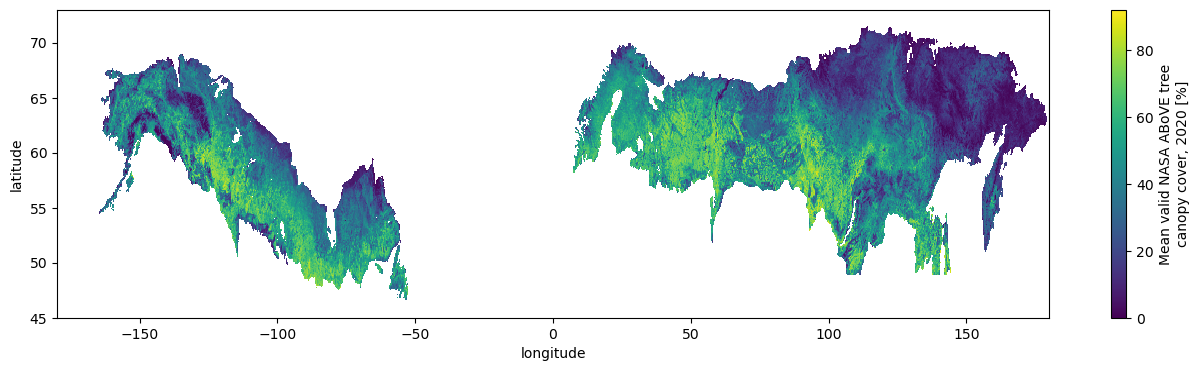

In [5]:
# Define your bounding box limits
min_lat, max_lat = 45, 73

# Create a boolean mask and drop values outside the box
mask = (
    (ds["latitude"] >= min_lat)
    & (ds["latitude"] <= max_lat)
)

from matplotlib import pyplot as plt
fig = plt.figure(figsize=(16,4))
ds.where(mask, drop=True).tree_canopy_cover_2020.plot()
plt.show()

# Site Selection Pipeline

### imports

In [7]:
# %pip install numpy pandas scipy xarray netCDF4 matplotlib

from pathlib import Path
import hashlib
import json
import os
import time
import uuid

import numpy as np
import pandas as pd
import xarray as xr
from scipy.spatial import cKDTree
from scipy.stats import rankdata

VERSION = "1.2.1"
EARTH_KM = 6371.0088
BANDS = ["low", "moderate", "high"]
CORE = ["air_temperature_mean", "snowfall_mean", "relative_humidity_mean", "wind_speed_mean"]
LABELS = {
    "air_temperature_mean": "Air temperature", "snowfall_mean": "Estimated snowfall",
    "relative_humidity_mean": "Relative humidity", "wind_speed_mean": "Wind speed",
    "air_temperature_daily_sd": "Daily temperature SD",
    "snowfall_daily_sd": "Daily snowfall SD", "relative_humidity_daily_sd": "Daily RH SD",
    "wind_speed_daily_sd": "Daily wind SD", "above_freezing_day_fraction": "Days above freezing",
    "freeze_thaw_day_fraction": "Freeze–thaw days", "snowfall_day_fraction": "Snowfall days",
}


from IPython.display import display, Image, FileLink

print("Notebook working directory:", Path.cwd())


Notebook working directory: /home/s1803229/Chapter_2/notebooks


### settings

Canopy bands are **low: 0–<25%**, **moderate: 25–50%**, and **high: >50%**.

In [18]:
INPUT_NC = Path("../../scratch/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc")
OUTPUT_DIR = Path("../../scratch/climate_site_selection/regional_site_selection")

WIDTH_KM = 400                         # Width along the central latitude of a box.
HEIGHT_KM = 400                        # North–south height.
CANDIDATE_SPACING_KM = 100             # Try 50 km for a finer search or 200 km boxes.
MIN_CANOPY_COVERAGE = 0.50             # at least x% of pixels have a valid canopy cover value
MIN_CANOPY_COVER = 10.0                # Minimum average tree canopy cover within a grid cell (%).
MIN_TEMPORAL_COVERAGE = 0.50           # every winter needs x% of days having valid measurement to be included
MIN_USABLE_FRACTION = 0.50             # Eligible area / entire box area.
MIN_CELL_SNOWFALL = None               # Optional minimum; same units as snowfall_mean.

SELECTION_VARIABLES = [
    "air_temperature_mean",
    "snowfall_mean",
    "relative_humidity_mean",
    "wind_speed_mean",
]
DIAGNOSTIC_VARIABLES = [
    "air_temperature_daily_sd", "snowfall_daily_sd",
    "relative_humidity_daily_sd", "wind_speed_daily_sd",
    "above_freezing_day_fraction", "freeze_thaw_day_fraction", "snowfall_day_fraction",
]
MAX_SPATIAL_SD = {}                    # Optional limits, e.g. {"air_temperature_mean": 3.0}.

SAMPLE_SIZES = list(range(5, 10))       # Evaluate every size from 8 through 16.

CLIMATE_COVERAGE_TOLERANCE = 0.25      # A candidate is represented when a selected site's
                                      # quantile differs by <=x in every climate variable.
TARGET_CLIMATE_COVERAGE = 0.85        # Recommend the smallest size representing >=x of candidates.
MIN_COVERAGE_GAIN = 0.05              # Flag improvements below x percentage point; not a stopping rule.

RANDOM_SEED = 1729
RESTARTS = 4                           # Independent optimisation attempts per size.
ITERATIONS = 20000                     # Proposals per optimisation attempt.
MAX_OVERLAP_FRACTION = 0.00             # fraction of two selected boxes that are allowed to overlap
MIN_BAND_FRACTION = 0.35                # Useful canopy band: fraction of eligible area.
CLIMATE_MATCH_TOLERANCE = CLIMATE_COVERAGE_TOLERANCE # Maximum difference in each climate's quantile to be considered canopy cover pairs
                                        # i.e. two regions to have similar climate, but one has low and the other has high canopy cover

INITIAL_TEMPERATURE = 0.03             # Simulated-annealing controls.
FINAL_TEMPERATURE = 0.0001
COMPLEMENT_PROPOSAL_FRACTION = 0.25    # this specifies how often the cLHS looks for a canopy cover pair for an existing candidate
OBJECTIVE_WEIGHTS = {
    "climate_gap": 1.0,        # Penalise the fraction of candidates not climatically represented.
    "marginal": 1.0,            # sampling across the range of each climate variable, primary goal
    "correlation": 0.2,         # retaining the relationships between climate variables found in candidate population
    "canopy_gap": 0.35,         # selecting canopy contrasts wherever suitable candidates exist
    "climate_spread": 0.05,     # choosing regions with less internal climate variation
}
FIGURE_DPI = 170

The next cell assembles these settings in memory. To change an experiment, edit and rerun the settings cell, then rerun the desired processing stage. That stage checks whether its preceding results can be reused.

In [19]:
def current_config():
    return {
        "input_nc": str(INPUT_NC),
        "output_dir": str(OUTPUT_DIR),
        "candidates": {
            "width_km": WIDTH_KM,
            "height_km": HEIGHT_KM,
            "spacing_km": CANDIDATE_SPACING_KM,
            "min_canopy_coverage": MIN_CANOPY_COVERAGE,
            "min_canopy_cover": MIN_CANOPY_COVER,
            "min_temporal_coverage": MIN_TEMPORAL_COVERAGE,
            "min_usable_fraction": MIN_USABLE_FRACTION,
            "min_cell_snowfall": MIN_CELL_SNOWFALL,
            "selection_variables": SELECTION_VARIABLES,
            "diagnostic_variables": DIAGNOSTIC_VARIABLES,
            "max_spatial_sd": MAX_SPATIAL_SD,
        },
        "selection": {
            "sample_sizes": SAMPLE_SIZES,
            "climate_coverage_tolerance": CLIMATE_COVERAGE_TOLERANCE,
            "target_climate_coverage": TARGET_CLIMATE_COVERAGE,
            "min_coverage_gain": MIN_COVERAGE_GAIN,
            "seed": RANDOM_SEED,
            "restarts": RESTARTS,
            "iterations": ITERATIONS,
            "initial_temperature": INITIAL_TEMPERATURE,
            "final_temperature": FINAL_TEMPERATURE,
            "max_overlap_fraction": MAX_OVERLAP_FRACTION,
            "min_band_fraction": MIN_BAND_FRACTION,
            "climate_match_quantile_tolerance": CLIMATE_MATCH_TOLERANCE,
            "complement_proposal_fraction": COMPLEMENT_PROPOSAL_FRACTION,
            "objective_weights": OBJECTIVE_WEIGHTS,
        },
        "diagnostics": {
            "dpi": FIGURE_DPI,
        },
    }


print("Input:", INPUT_NC.resolve())
print("Results:", OUTPUT_DIR.resolve())

Input: /scratch/s1803229/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc
Results: /scratch/s1803229/climate_site_selection/regional_site_selection


## 3. Shared data and area functions

Means and spatial standard deviations use spherical cell-area weights, i.e. cell areas are calculated using Earth approximated as a sphere and weighted accordingly. A spatial SD describes variation **between cells in a region**; it is distinct from the input daily SD, which describes **variation through time**.

In [20]:
def log(message):
    # Show progress immediately, with the current time.
    print(time.strftime("[%H:%M:%S] ") + str(message), flush=True)


def digest(value):
    # Give a combination of settings a repeatable experiment ID.
    # Later code uses this ID in the results-folder name.
    text = json.dumps(value, sort_keys=True, allow_nan=False)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:16]


def atomic_json(path, value):
    # Save a small record: settings, completed variables, or finished experiments.
    # Later code reads these records to decide what can be reused or skipped.
    path = Path(path)
    temp = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")

    try:
        temp.write_text(
            json.dumps(value, indent=2, allow_nan=False),
            encoding="utf-8",
        )  # Write to a temporary file first.
        os.replace(temp, path)  # Replace the final file only when writing succeeds.
    finally:
        temp.unlink(missing_ok=True)  # Remove any leftover temporary file.


def atomic_csv(path, table):
    # Save actual tables, including candidate summaries and selected sites.
    # The temporary-file approach protects an existing table from a partial write.
    path = Path(path)
    temp = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")

    try:
        table.to_csv(temp, index=False)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def source_signature(path):
    # Record which input NetCDF this experiment uses.
    # Include this information in the experiment ID so an updated NetCDF
    # does not accidentally reuse results calculated from an older file.
    p = Path(path).expanduser().resolve()
    s = p.stat()

    return {
        "path": str(p),           # Full input-file location.
        "bytes": s.st_size,       # File size.
        "mtime_ns": s.st_mtime_ns,  # Last modification time.
    }  # This checks file metadata, without reading the whole NetCDF.


def edges(centres):
    # Convert cell-centre coordinates into cell boundaries.
    # Example: centres [10, 11, 12] → edges [9.5, 10.5, 11.5, 12.5].
    # We need boundaries to calculate areas and align study boxes to whole cells.
    centres = np.asarray(centres, dtype=np.float64)

    if centres.ndim != 1 or centres.size < 2:
        raise ValueError("Expected a 1D coordinate array with at least two centres")

    d = np.diff(centres)  # Spacing between neighbouring cell centres.

    if (
        not np.all(np.isfinite(centres))
        or not np.all(d > 0)
        or not np.allclose(d, np.median(d), rtol=1e-4, atol=1e-6)
    ):
        raise ValueError(
            "Expected regular, increasing, unique latitude and longitude coordinates"
        )

    return np.r_[
        centres[0] - d[0] / 2,           # Outer boundary before the first centre.
        (centres[:-1] + centres[1:]) / 2,  # Boundaries between neighbouring centres.
        centres[-1] + d[-1] / 2,         # Outer boundary after the last centre.
    ]


def open_grid(path):
    # Open the NetCDF and arrange its grid consistently for later calculations.
    ds = xr.open_dataset(path)

    try:
        for name in ["latitude", "longitude"]:
            if ds[name].dims != (name,):
                raise ValueError(f"Expected 1D {name} coordinates")

        ds = ds.assign_coords(
            longitude=(ds.longitude + 180) % 360 - 180
        )  # Express longitude as −180 to 180 rather than 0 to 360.

        ds = ds.sortby("latitude").sortby("longitude")
        # Data now run south → north and west → east.

        edges(ds.latitude.values)
        edges(ds.longitude.values)
        # Check that both coordinates have regular spacing.

        return ds  # Return the open dataset for the caller to use and close.

    except Exception:
        ds.close()  # Close the file if preparation fails.
        raise


def map_values(ds, name):
    # Load one variable as a numerical map, with rows = latitude, columns = longitude.
    a = ds[name]

    if set(a.dims) != {"latitude", "longitude"}:
        raise ValueError(
            f"{name} has dimensions {a.dims}; "
            "use the collapsed 2D climatology NetCDF"
        )

    return (
        a.transpose("latitude", "longitude")
        .values.astype(np.float64)
    )  # Load this map into memory, using precision suited to the calculations.


def read_domain(ds, cfg):
    # Create a True/False map identifying cells that satisfy all eligibility rules.
    cc = map_values(ds, "tree_canopy_cover_2020")
    cov = map_values(ds, "tree_canopy_coverage_fraction")

    valid = (
        np.isfinite(cc)
        & (cc >= cfg["min_canopy_cover"])  # At least 10% canopy with your settings.
        & (cc <= 100)
    )

    valid &= (
        np.isfinite(cov)
        & (cov >= cfg["min_canopy_coverage"])  # Enough valid canopy-map coverage.
        & (cov <= 1.001)  # Small allowance for numerical rounding around 1.
    )  # Each &= adds another requirement; rejected cells remain rejected.

    for name in CORE:
        a = map_values(ds, name)
        valid &= np.isfinite(a)  # Require valid temperature, snowfall, RH and wind.

        if name in ["snowfall_mean", "wind_speed_mean"]:
            valid &= a >= 0

        if name == "relative_humidity_mean":
            valid &= (a >= 0) & (a <= 100)

        if cfg["min_temporal_coverage"] is not None:
            coverage_name = name + "_min_period_valid_fraction"

            if coverage_name not in ds:
                raise ValueError(
                    f"Missing {coverage_name}; use the combined script's NetCDF "
                    "or set MIN_TEMPORAL_COVERAGE = None to disable this check"
                )

            frac = map_values(ds, coverage_name)
            valid &= (
                np.isfinite(frac)
                & (frac >= cfg["min_temporal_coverage"])
            )  # Enough valid daily records in every original winter–period.

    for name in cfg["selection_variables"]:
        if name not in CORE:
            valid &= np.isfinite(map_values(ds, name))
            # Require valid values for any additional selection variables.

    if cfg["min_cell_snowfall"] is not None:
        valid &= (
            map_values(ds, "snowfall_mean")
            >= cfg["min_cell_snowfall"]
        )  # Apply a snowfall minimum only if you specify one.

    if not valid.any():
        raise ValueError(
            "No eligible cells remain; inspect data coverage and thresholds"
        )

    return cc, valid  # Return canopy cover and the eligibility mask.


def rect_area(w, s, e, n):
    # Calculate a latitude/longitude rectangle's area in km².
    # Used for cell-area weights, study-box areas and box overlap.
    return (
        EARTH_KM**2
        * np.deg2rad(np.asarray(e) - np.asarray(w))
        * (
            np.sin(np.deg2rad(n))
            - np.sin(np.deg2rad(s))
        )
    )  # Account for longitude lines converging toward the poles.


def integral(a):
    # Prepare cumulative sums once, so thousands of boxes can be summarised quickly.
    out = np.zeros(
        (a.shape[0] + 1, a.shape[1] + 1),
        dtype=np.float64,
    )  # The extra zero row and column make edge calculations straightforward.

    out[1:, 1:] = np.cumsum(
        np.cumsum(a, axis=0),
        axis=1,
    )

    return out


def rect_sum(table, r0, r1, c0, c1):
    # Retrieve a box's sum from the cumulative table using only four entries.
    # Equivalent to summing the original array over [r0:r1, c0:c1].
    return (
        table[r1, c1]
        - table[r0, c1]
        - table[r1, c0]
        + table[r0, c0]
    )

## 4. Candidate footprint construction

Centres are placed on a regular north–south lattice. East–west spacing adjusts with latitude to maintain approximately constant kilometre spacing. The rectangles snap outward to the NetCDF grid edges so they contain whole cells; their actual sizes and boundaries are recorded.

The width refers to the central latitude. These are latitude/longitude rectangles, so width varies slightly between the northern and southern edges. Boxes must fit fully inside the input domain; dateline-crossing boxes are skipped.

Each box is screened for usable area, then described by regional climate means, spatial variability and canopy-band fractions. Canopy bands classify the **aggregated grid-cell canopy cover**; finer canopy contrasts may need checking in the native canopy map later. Climate variability receives a mild selection penalty rather than a hard cutoff by default.

In [21]:
def candidate_boxes(lat, lon, valid, cfg):
    le, oe = edges(lat), edges(lon)
    rows, cols = np.where(valid)

    step = cfg["spacing_km"]
    width, height = cfg["width_km"], cfg["height_km"]

    if min(step, width, height) <= 0:
        raise ValueError(
            "Footprint dimensions and candidate spacing must be positive"
        )

    dlat = np.rad2deg(step / EARTH_KM)
    half_h = np.rad2deg(height / (2 * EARTH_KM))

    lat_min, lat_max = lat[rows.min()], lat[rows.max()]
    lon_min, lon_max = lon[cols.min()], lon[cols.max()]

    records, seen = [], set()
    skipped = 0

    centres_lat = np.arange(
        np.ceil(lat_min / dlat) * dlat,
        lat_max + 1e-10,
        dlat,
    )  # Place centres on a repeatable grid with the requested spacing.

    for cy in centres_lat:
        cos_lat = np.cos(np.deg2rad(cy))
        dlon = np.rad2deg(step / (EARTH_KM * cos_lat))
        half_w = np.rad2deg(width / (2 * EARTH_KM * cos_lat))
        # Adjust longitude spacing and box width for latitude.

        centres_lon = np.arange(
            np.ceil(lon_min / dlon) * dlon,
            lon_max + 1e-10,
            dlon,
        )

        for cx in centres_lon:
            west, east = cx - half_w, cx + half_w
            south, north = cy - half_h, cy + half_h

            if (
                west < max(-180, oe[0])
                or east > min(180, oe[-1])
                or south < max(-90, le[0])
                or north > min(90, le[-1])
            ):
                skipped += 1
                continue  # Exclude incomplete boxes and dateline-crossing boxes.

            c0 = max(0, np.searchsorted(oe, west, side="right") - 1)
            c1 = min(len(lon), np.searchsorted(oe, east, side="left"))
            r0 = max(0, np.searchsorted(le, south, side="right") - 1)
            r1 = min(len(lat), np.searchsorted(le, north, side="left"))
            # Snap boundaries outward so every included cell is complete.

            box_indices = (r0, r1, c0, c1)

            if box_indices in seen or r0 == r1 or c0 == c1:
                continue

            seen.add(box_indices)

            w, e = oe[c0], oe[c1]
            s, n = le[r0], le[r1]
            center_lat, center_lon = (s + n) / 2, (w + e) / 2

            records.append({
                "candidate_id": f"C{len(records) + 1:06d}",
                "longitude": center_lon,
                "latitude": center_lat,
                "west": w,
                "south": s,
                "east": e,
                "north": n,
                "row0": r0,
                "row1": r1,
                "col0": c0,
                "col1": c1,
                "area_km2": float(rect_area(w, s, e, n)),
                "width_at_centre_km": (
                    EARTH_KM
                    * np.deg2rad(e - w)
                    * np.cos(np.deg2rad(center_lat))
                ),
                "height_km": EARTH_KM * np.deg2rad(n - s),
            })

    if not records:
        raise ValueError(
            "No complete candidate boxes fit this grid; "
            "reduce width/height or spacing"
        )

    log(
        f"Generated {len(records):,} unique grid-aligned boxes; "
        f"skipped {skipped:,} at domain/dateline boundaries"
    )

    return pd.DataFrame(records)


def geojson(table, path):
    # Save geographic box boundaries for plotting or opening in GIS software.
    features = []

    for _, row in table.iterrows():
        w, s, e, n = [
            float(row[k]) for k in ["west", "south", "east", "north"]
        ]

        props = {
            k: (
                None if pd.isna(v)
                else v.item() if isinstance(v, np.generic)
                else v
            )
            for k, v in row.items()
        }

        features.append({
            "type": "Feature",
            "properties": props,
            "geometry": {
                "type": "Polygon",
                "coordinates": [
                    [[w, s], [e, s], [e, n], [w, n], [w, s]]
                ],
            },
        })

    atomic_json(
        path,
        {"type": "FeatureCollection", "features": features},
    )


def build_candidates(config):
    cfg = config["candidates"]

    signature = {
        "version": VERSION,
        "summary_method": "climate_and_canopy_means_v2",
        "source": source_signature(config["input_nc"]),
        "candidates": cfg,
    }

    folder = Path(config["output_dir"]) / (
        "candidates_" + digest(signature)
    )
    folder.mkdir(parents=True, exist_ok=True)

    manifest = folder / "manifest.json"

    if manifest.exists():
        log(f"Reusing completed candidate catalogue: {folder}")
        return folder

    checkpoint = folder / "candidate_progress.csv"
    done_path = folder / "progress.json"

    with open_grid(config["input_nc"]) as ds:
        lat, lon = ds.latitude.values, ds.longitude.values
        cc, valid = read_domain(ds, cfg)
        le, oe = edges(lat), edges(lon)

        row_area = (
            EARTH_KM**2
            * np.deg2rad(oe[1] - oe[0])
            * np.diff(np.sin(np.deg2rad(le)))
        )
        weights = np.broadcast_to(
            row_area[:, None],
            (len(lat), len(lon)),
        )  # Physical area of each grid cell, in km².

        if checkpoint.exists() and done_path.exists():
            progress = json.loads(done_path.read_text())
            table = pd.read_csv(checkpoint)
            completed = progress["completed_variables"]

            log(
                f"Resuming candidate summaries after "
                f"{len(completed)} variables"
            )

        else:
            table = candidate_boxes(lat, lon, valid, cfg)

            idx = [
                table[k].to_numpy(dtype=int)
                for k in ["row0", "row1", "col0", "col1"]
            ]

            table["usable_area_km2"] = rect_sum(
                integral(weights * valid), *idx
            )
            table["usable_fraction"] = (
                table.usable_area_km2 / table.area_km2
            )

            band_masks = [
                (cc >= cfg["min_canopy_cover"]) & (cc < 25),
                (cc >= 25) & (cc <= 50),
                cc > 50,
            ]

            for band, mask in zip(BANDS, band_masks):
                area = rect_sum(
                    integral(weights * valid * mask), *idx
                )

                table[band + "_area_km2"] = area
                table[band + "_fraction"] = np.divide(
                    area,
                    table.usable_area_km2.to_numpy(),
                    out=np.zeros(len(table)),
                    where=table.usable_area_km2.to_numpy() > 0,
                )  # Band area divided by eligible area, not the full box.

            table["coverage_pass"] = (
                (table.usable_area_km2 > 0)
                & (
                    table.usable_fraction
                    >= cfg["min_usable_fraction"]
                )
            )  # No separate minimum-cell-count requirement.

            atomic_csv(folder / "footprint_screening.csv", table)

            table = table.loc[
                table.coverage_pass
            ].reset_index(drop=True)

            if table.empty:
                raise ValueError(
                    "No boxes pass usable coverage. Inspect "
                    f"{folder / 'footprint_screening.csv'}"
                )

            completed = []
            atomic_csv(checkpoint, table)
            atomic_json(
                done_path,
                {"completed_variables": completed},
            )

        idx = [
            table[k].to_numpy(dtype=int)
            for k in ["row0", "row1", "col0", "col1"]
        ]

        required = list(dict.fromkeys(
            cfg["selection_variables"]
            + ["tree_canopy_cover_2020"]
            + list(cfg["max_spatial_sd"])
        ))  # Include any variables with explicit spatial-SD limits.

        missing_required = [
            name for name in required if name not in ds
        ]

        if missing_required:
            raise ValueError(
                "Required variables absent from NetCDF: "
                + ", ".join(missing_required)
            )

        requested = list(dict.fromkeys(
            required + cfg["diagnostic_variables"]
        ))
        names = [name for name in requested if name in ds]
        missing = [name for name in requested if name not in ds]
        units = {
            name: ds[name].attrs.get("units", "")
            for name in names
        }

        if missing:
            log(
                "Optional diagnostic variables absent: "
                + ", ".join(missing)
            )

        for name in names:
            if name in completed:
                continue  # Reuse variables already saved in the checkpoint.

            a = map_values(ds, name)
            support = valid & np.isfinite(a)
            wa = weights * support

            denominator = rect_sum(integral(wa), *idx)

            offset = float(np.median(a[support])) if support.any() else 0.0
            centered = np.where(support, a - offset, 0.0)
            # Subtract a reference value to improve numerical precision.

            mean = np.divide(
                rect_sum(integral(wa * centered), *idx),
                denominator,
                out=np.full(len(table), np.nan),
                where=denominator > 0,
            )

            second = np.divide(
                rect_sum(integral(wa * centered**2), *idx),
                denominator,
                out=np.full(len(table), np.nan),
                where=denominator > 0,
            )

            table[name] = mean + offset
            table[name + "__spatial_sd"] = np.sqrt(
                np.maximum(second - mean**2, 0)
            )
            table[name + "__valid_fraction"] = (
                denominator / table.usable_area_km2
            )

            completed.append(name)
            atomic_csv(checkpoint, table)
            atomic_json(
                done_path,
                {"completed_variables": completed},
            )

            log(f"Summarised {name} for {len(table):,} regions")

        table["climate_spread_score"] = 0.0
        active_spread_variables = 0

        for name in cfg["selection_variables"]:
            regional_sd = table[name].std(ddof=0)

            if np.isfinite(regional_sd) and regional_sd > 0:
                table["climate_spread_score"] += (
                    table[name + "__spatial_sd"] / regional_sd
                ) ** 2
                active_spread_variables += 1

        if active_spread_variables:
            table["climate_spread_score"] = np.sqrt(
                table.climate_spread_score / active_spread_variables
            )  # Combined measure of within-box climate variation.

        table["passes_climate_limits"] = True

        for name, limit in cfg["max_spatial_sd"].items():
            table["passes_climate_limits"] &= (
                table[name + "__spatial_sd"] <= limit
            )

        atomic_csv(
            folder / "candidate_summaries_before_climate_limits.csv",
            table,
        )

        table = table.loc[
            table.passes_climate_limits
        ].reset_index(drop=True)

        if table.empty:
            raise ValueError(
                "No candidates pass the configured climate-spread limits"
            )

        atomic_csv(folder / "candidates.csv", table)

        # Save smaller climate maps for the later coloured climate-region map.
        stride = max(
            1, int(np.ceil(max(len(lat), len(lon)) / 900))
        )
        small_valid = valid[::stride, ::stride]
        map_variables = cfg["selection_variables"]

        climate_maps = np.stack([
            np.where(
                small_valid,
                map_values(ds, name)[::stride, ::stride],
                np.nan,
            ).astype("float32")
            for name in map_variables
        ])  # Dimensions: variable, latitude, longitude.

        map_path = folder / "map_background.npz"
        temporary = folder / (
            "map_background." + uuid.uuid4().hex + ".tmp.npz"
        )

        try:
            np.savez_compressed(
                temporary,
                latitude=lat[::stride],
                longitude=lon[::stride],
                eligible=small_valid,
                climate_variables=np.asarray(map_variables, dtype=str),
                climate_maps=climate_maps,
            )
            os.replace(temporary, map_path)
        finally:
            temporary.unlink(missing_ok=True)

        geojson(table, folder / "candidates.geojson")

        atomic_json(manifest, {
            **signature,
            "candidate_count": len(table),
            "units": units,
            "absent_diagnostics": missing,
            "selection_variables": cfg["selection_variables"],
            "area_definition": (
                "Spherical latitude/longitude rectangles snapped outward "
                "to grid edges; width is at centre latitude"
            ),
            "climate_population": (
                "Approximately equal-distance lattice of eligible candidate "
                "footprints; not individual cells or area-weighted land population"
            ),
        })  # Mark the candidate stage complete only after all outputs are saved.

    log(f"Saved candidate catalogue: {folder}")
    return folder

### Run the candidate stage

This stage checkpoints after each variable. If interrupted, rerunning it recreates the eligibility mask and continues the unfinished summaries. Changing footprint or eligibility settings creates a separate results directory. The original daily climate files and canopy TIFFs are not needed.

In [22]:
config = current_config()
candidate_dir = build_candidates(config)
candidates = pd.read_csv(candidate_dir / "candidates.csv")
print(f"{len(candidates):,} eligible candidate regions")
print("Saved in:", candidate_dir.resolve())
display(candidates.head())


[14:22:44] Generated 5,440 unique grid-aligned boxes; skipped 42 at domain/dateline boundaries
[14:22:45] Summarised air_temperature_mean for 1,513 regions
[14:22:46] Summarised snowfall_mean for 1,513 regions
[14:22:46] Summarised relative_humidity_mean for 1,513 regions
[14:22:46] Summarised wind_speed_mean for 1,513 regions
[14:22:47] Summarised tree_canopy_cover_2020 for 1,513 regions
[14:22:47] Summarised air_temperature_daily_sd for 1,513 regions
[14:22:47] Summarised snowfall_daily_sd for 1,513 regions
[14:22:47] Summarised relative_humidity_daily_sd for 1,513 regions
[14:22:48] Summarised wind_speed_daily_sd for 1,513 regions
[14:22:48] Summarised above_freezing_day_fraction for 1,513 regions
[14:22:48] Summarised freeze_thaw_day_fraction for 1,513 regions
[14:22:49] Summarised snowfall_day_fraction for 1,513 regions
[14:22:50] Saved candidate catalogue: ../../scratch/climate_site_selection/regional_site_selection/candidates_ce67aa33f7ea25a1
1,513 eligible candidate regions
Sav

,candidate_id,longitude,latitude,west,south,east,north,row0,row1,col0,...,above_freezing_day_fraction__spatial_sd,above_freezing_day_fraction__valid_fraction,freeze_thaw_day_fraction,freeze_thaw_day_fraction__spatial_sd,freeze_thaw_day_fraction__valid_fraction,snowfall_day_fraction,snowfall_day_fraction__spatial_sd,snowfall_day_fraction__valid_fraction,climate_spread_score,passes_climate_limits
0,C000576,-85.60,48.55,-88.4,46.7,-82.8,50.4,1367,1404,916,...,0.030688,1.0,0.199420,0.018209,1.0,0.626995,0.031896,1.0,0.458826,True
1,C000577,-84.25,48.55,-87.0,46.7,-81.5,50.4,1367,1404,930,...,0.026621,1.0,0.206878,0.014303,1.0,0.621151,0.025075,1.0,0.355718,True
2,C000578,-82.90,48.55,-85.7,46.7,-80.1,50.4,1367,1404,943,...,0.025602,1.0,0.206289,0.016075,1.0,0.629447,0.027381,1.0,0.265916,True
3,C000579,-81.55,48.55,-84.3,46.7,-78.8,50.4,1367,1404,957,...,0.027934,1.0,0.200471,0.019329,1.0,0.640939,0.028244,1.0,0.194748,True
4,C000580,-80.15,48.55,-82.9,46.7,-77.4,50.4,1367,1404,971,...,0.031078,1.0,0.193399,0.020090,1.0,0.653208,0.022630,1.0,0.206030,True


## 5. cLHS selection and canopy complements

The selection targets the distribution of **candidate-region climate means**, giving each candidate equal weight. Daily variability and thaw metrics are diagnostic by default; add them to `SELECTION_VARIABLES` if they should also guide selection.

The continuous-variable cLHS objective seeks one region per marginal quantile stratum and preserves climate correlations. Regional extensions penalise unresolved canopy contrasts and large within-region climatic spread. Footprint overlap is prohibited throughout optimisation.

A canopy band can be supplied by a selected region itself or by another selected region within `CLIMATE_MATCH_TOLERANCE` in **every** selected climate variable's empirical quantile. This encourages complementary regions within the total budget. An eight-region selection contains exactly eight regions, including any partners.

Quantile proximity (between two regions with "similar" climates but different canopy cover) is an operational screening rule. Inspect actual climatic values and regional gradients before interpreting canopy comparisons. Potential canopy availability is local to each region; all possible partners need not be jointly feasible. Remaining gaps and optional complement suggestions are saved without adding downloads or exceeding the site budget.

In [23]:
def overlap_against(box, others):
    # Intersection fraction relative to the smaller footprint; vectorized.
    others=np.asarray(others)
    if others.size==0:
        return np.empty(0)
    w=np.maximum(box[0],others[:,0]); s=np.maximum(box[1],others[:,1])
    e=np.minimum(box[2],others[:,2]); n=np.minimum(box[3],others[:,3])
    inter=rect_area(w,s,np.maximum(w,e),np.maximum(s,n))
    smaller=np.minimum(rect_area(*box),rect_area(others[:,0],others[:,1],others[:,2],others[:,3]))
    return inter/smaller


def corr_matrix(x):
    x=x-x.mean(axis=0)
    norm=np.sqrt((x*x).sum(axis=0))
    z=np.divide(x,norm,out=np.zeros_like(x),where=norm>1e-12)
    return z.T@z


class Design:
    """Continuous-variable cLHS with explicit regional constraints and penalties."""
    def __init__(self,table,variables,cfg,n):
        self.table=table
        self.cfg=cfg
        self.n=n
        raw = table[variables].to_numpy(float)

        if not np.isfinite(raw).all():
            raise ValueError(
                "Candidate selection variables contain missing/nonfinite values"
            )

        active = np.std(raw, axis=0) > 1e-12
        self.variables = list(np.array(variables)[active])
        self.dropped = list(np.array(variables)[~active])
        raw = raw[:, active]

        if raw.shape[1] == 0:
            raise ValueError("All selection variables are constant")
        self.x=(raw-raw.mean(axis=0))/raw.std(axis=0)
        self.ranks=np.column_stack([(rankdata(raw[:,j],method="average")-.5)/len(raw)
                                    for j in range(raw.shape[1])])
        self.bins=np.column_stack([np.searchsorted(np.quantile(raw[:,j],np.arange(1,n)/n),raw[:,j],side="right")
                                   for j in range(raw.shape[1])])
        self.corr=corr_matrix(self.x)
        self.upper=np.triu_indices(raw.shape[1],1)
        self.boxes=table[["west","south","east","north"]].to_numpy(float)
        self.available = np.column_stack([
            table[b + "_fraction"].to_numpy() >= cfg["min_band_fraction"]
            for b in BANDS
        ])
        
        self.tree=cKDTree(self.ranks)
        self.coverage_tolerance = cfg["climate_coverage_tolerance"]
        self.coverage_neighbours = {}  # Cache which candidates each site represents.
        self.possible=self.available.copy()
        self.tolerance=cfg["climate_match_quantile_tolerance"]
        for i in range(len(table)):
            neighbours=np.asarray(self.tree.query_ball_point(self.ranks[i],self.tolerance,p=np.inf),dtype=int)
            allowed=overlap_against(self.boxes[i],self.boxes[neighbours])<=cfg["max_overlap_fraction"]+1e-12
            neighbours=neighbours[allowed]
            if len(neighbours):
                self.possible[i]|=self.available[neighbours].any(axis=0)
        quality=table.climate_spread_score.to_numpy(float)
        self.quality=(rankdata(quality,method="average")-.5)/len(quality)

    def canopy_support(self,ids):
        match=np.max(np.abs(self.ranks[ids,None,:]-self.ranks[None,ids,:]),axis=2)<=self.tolerance+1e-12
        support=(match.astype(int)@self.available[ids].astype(int))>0
        missing=self.possible[ids]&~support
        return match,support,missing

    def climate_coverage(self, ids):
        represented = np.zeros(len(self.table), dtype=bool)

        for site in ids:
            site = int(site)

            if site not in self.coverage_neighbours:
                self.coverage_neighbours[site] = np.asarray(
                    self.tree.query_ball_point(
                        self.ranks[site],
                        self.coverage_tolerance + 1e-12,
                        p=np.inf,
                    ),
                    dtype=int,
                )  # Require every climate variable to fall within the tolerance.

            represented[self.coverage_neighbours[site]] = True
            # A candidate counts once, even if several selected sites represent it.

        return float(represented.mean())
        # Fraction of the entire candidate catalogue represented by this selection.

    def components(self, ids):
        marginal = np.mean([
            np.abs(
                np.bincount(self.bins[ids, j], minlength=self.n) - 1
            ).mean()
            for j in range(self.x.shape[1])
        ])  # Prefer one selected site in each climate quantile stratum.

        correlation = (
            float(np.mean(np.abs(
                corr_matrix(self.x[ids])[self.upper]
                - self.corr[self.upper]
            )))
            if len(self.upper[0]) else 0.0
        )

        _, _, missing = self.canopy_support(ids)
        canopy = float(
            missing.sum() / max(1, self.possible[ids].sum())
        )

        consistency = float(self.quality[ids].mean())

        parts = {
            "climate_gap": 1.0 - self.climate_coverage(ids),
            "marginal": float(marginal),
            "correlation": correlation,
            "canopy_gap": canopy,
            "climate_spread": consistency,
        }

        parts["total"] = sum(
            value * self.cfg["objective_weights"][name]
            for name, value in parts.items()
        )

        return parts

    def compatible(self,new,others):
        return not len(others) or bool(np.all(overlap_against(self.boxes[new],self.boxes[others])<=self.cfg["max_overlap_fraction"]+1e-12))

    def initial(self,rng):
        for attempt in range(100):
            ids=[]
            for i in rng.permutation(len(self.table)):
                if self.compatible(i,ids):
                    ids.append(i)
                    if len(ids)==self.n:
                        return np.array(ids,dtype=int)
        raise ValueError(f"Could not initialise {self.n} compatible regions. Reduce n, footprint size, or relax max_overlap_fraction")

    def anneal(self,seed):
        rng=np.random.default_rng(seed)
        ids=self.initial(rng)
        score=self.components(ids)["total"]
        best,best_score=ids.copy(),score
        trace=[]
        iterations=self.cfg["iterations"]
        start=self.cfg["initial_temperature"]
        end=self.cfg["final_temperature"]
        for i in range(iterations):
            slot=int(rng.integers(self.n)); new=int(rng.integers(len(self.table)))
            others=np.delete(ids,slot)
            # Occasionally propose a similar-climate partner with complementary canopy.
            if rng.random() < self.cfg["complement_proposal_fraction"]:
                anchor = int(rng.choice(others))
                options = np.asarray(
                    self.tree.query_ball_point(
                        self.ranks[anchor], self.tolerance, p=np.inf
                    ),
                    dtype=int,
                )

                # Only consider new regions compatible with all retained boxes.
                options = np.asarray([
                    option for option in options
                    if option not in ids and self.compatible(option, others)
                ], dtype=int)

                if len(options):
                    gains = (
                        self.available[options] & ~self.available[anchor]
                    ).sum(axis=1)

                    if gains.max() > 0:
                        options = options[gains == gains.max()]
                        new = int(rng.choice(options))
                # Otherwise retain the ordinary random proposal.
            if new in ids or not self.compatible(new,others):
                continue
            proposal=ids.copy();proposal[slot]=new
            candidate_score=self.components(proposal)["total"]
            temperature=start*(end/start)**(i/max(1,iterations-1))
            if candidate_score<=score or rng.random()<np.exp(min(0,(score-candidate_score)/temperature)):
                ids,score=proposal,candidate_score
            if score<best_score:
                best,best_score=ids.copy(),score
            if i%max(1,iterations//200)==0:
                trace.append({"iteration":i,"current_objective":score,"best_objective":best_score})
        trace.append({"iteration":iterations,"current_objective":score,"best_objective":best_score})
        return best,self.components(best),pd.DataFrame(trace)


### Selection outputs and repeatability

Several independent optimisation restarts are run for each sample size. The lowest full objective is retained, with component scores and optimisation traces saved. These are heuristic designs; a globally optimal result is not guaranteed.

Constant variables are omitted from the optimiser. Tied values can make some quantile strata unattainable, and the diagnostics report attainable as well as nominal counts. Sample sets of different sizes are independently optimised and are **not nested**.

In [24]:
def selection_table(design,ids):
    out=design.table.iloc[ids].copy().reset_index(drop=True)
    out.insert(0,"site_id",[f"S{i+1:02d}" for i in range(len(ids))])
    match,support,missing=design.canopy_support(ids)
    for k,b in enumerate(BANDS):
        out[b+"_supported_here"]=design.available[ids,k]
        out[b+"_supported_in_climate_group"]=support[:,k]
        out[b+"_potentially_available"]=design.possible[ids,k]
        out[b+"_missing_despite_candidates"]=missing[:,k]
    out["similar_climate_selected_sites"]=[",".join(out.site_id[match[i]& (np.arange(len(ids))!=i)]) for i in range(len(ids))]
    return out


def distribution_metrics(design,ids):
    records=[]
    for j,name in enumerate(design.variables):
        population=np.sort(design.table[name].to_numpy(float))
        sample=np.sort(design.table.iloc[ids][name].to_numpy(float))
        union=np.unique(np.r_[population,sample])
        ks=np.max(np.abs(np.searchsorted(population,union,side="right")/len(population)-
                         np.searchsorted(sample,union,side="right")/len(sample)))
        fixed_edges=np.quantile(population,np.arange(1,10)/10)
        pop_deciles=np.searchsorted(fixed_edges,population,side="right")
        selected_deciles=np.searchsorted(fixed_edges,sample,side="right")
        records.append({"variable":name,"cdf_gap":float(ks),
            "occupied_deciles":len(np.unique(selected_deciles)),"attainable_deciles":len(np.unique(pop_deciles)),
            "decile_coverage":len(np.unique(selected_deciles))/len(np.unique(pop_deciles)),
            "occupied_clhs_strata":len(np.unique(design.bins[ids,j])),
            "attainable_clhs_strata":len(np.unique(design.bins[:,j])),"requested_strata":len(ids),
            "population_min":float(population[0]),"population_max":float(population[-1]),
            "sample_min":float(sample[0]),"sample_max":float(sample[-1])})
    return pd.DataFrame(records)


def complement_suggestions(design,ids,selected):
    records=[]
    _,_,missing=design.canopy_support(ids)
    for k,anchor in enumerate(ids):
        if not missing[k].any():
            continue
        neighbours=design.tree.query_ball_point(design.ranks[anchor],design.tolerance,p=np.inf)
        choices=[]
        for j in neighbours:
            if j in ids or not design.compatible(j,ids):
                continue
            gained=design.available[j]&missing[k]
            if gained.any():
                distance=float(np.max(np.abs(design.ranks[j]-design.ranks[anchor])))
                choices.append((-int(gained.sum()),distance,j,gained))
        for _,distance,j,gained in sorted(choices,key=lambda a:a[:3])[:3]:
            row=design.table.iloc[j]
            records.append({"anchor_site":selected.iloc[k].site_id,"candidate_id":row.candidate_id,
                "additional_bands":",".join(np.array(BANDS)[gained]),"max_climate_quantile_difference":distance,
                "west":row.west,"south":row.south,"east":row.east,"north":row.north,
                "note":"Suggestion only; not added to the selected count. Replace a site or increase budget and rerun."})
    return pd.DataFrame(records,columns=["anchor_site","candidate_id","additional_bands","max_climate_quantile_difference",
        "west","south","east","north","note"])


def select_sites(config, candidate_dir=None):
    folder = Path(candidate_dir) if candidate_dir else build_candidates(config)
    table = pd.read_csv(folder / "candidates.csv")
    manifest = json.loads((folder / "manifest.json").read_text())
    cfg = config["selection"]
    sizes = sorted(set(cfg["sample_sizes"]))

    if not sizes or min(sizes) < 2 or max(sizes) > len(table):
        raise ValueError(
            "Sample sizes must be at least 2 and no larger than candidate count"
        )

    if (
        cfg["restarts"] < 1
        or cfg["iterations"] < 1
        or min(cfg["initial_temperature"], cfg["final_temperature"]) <= 0
    ):
        raise ValueError("Use positive iterations, restarts and temperatures")

    target = cfg["target_climate_coverage"]

    if not 0 < target <= 1:
        raise ValueError("Target climate coverage must be greater than 0 and <= 1")
    if not 0 <= cfg["climate_coverage_tolerance"] <= 1:
        raise ValueError("Climate coverage tolerance must be between 0 and 1")
    if not 0 <= cfg["min_coverage_gain"] <= 1:
        raise ValueError("Minimum coverage gain must be between 0 and 1")

    signature = {
        "version": VERSION,
        "candidate_manifest": manifest,
        "candidate_csv_sha256": hashlib.sha256(
            (folder / "candidates.csv").read_bytes()
        ).hexdigest(),
        "selection": cfg,
        "initialisation": "independent_random_restarts",
        "decision_method": "minimum_total_objective_v2",
    }

    out = folder / ("selection_" + digest(signature))
    out.mkdir(exist_ok=True)

    if (out / "manifest.json").exists():
        recommendation = json.loads(
            (out / "recommendation.json").read_text()
        )
        log(f"Reusing completed selections: {out}")
        log(recommendation["message"])
        return out

    run_records = []
    size_records = []

    for n in sizes:
        log(f"Preparing cLHS for {n} sites")
        design = Design(table, manifest["selection_variables"], cfg, n)

        if design.dropped:
            log("Constant variables omitted: " + ", ".join(design.dropped))

        solutions = []

        for restart in range(cfg["restarts"]):
            seed = int(cfg["seed"] + n * 1000 + restart)
            prefix = out / f"n{n:02d}_restart{restart + 1:02d}"
            saved = prefix.with_suffix(".json")

            if saved.exists():
                record = json.loads(saved.read_text())
                ids = np.asarray(record["row_indices"], dtype=int)
                parts = design.components(ids)
                log(f"Reusing n={n}, restart={restart + 1}")

            else:
                ids, parts, trace = design.anneal(seed)
                # Each restart begins with a fresh random selection.

                atomic_csv(str(prefix) + "_trace.csv", trace)
                atomic_json(saved, {
                    "row_indices": ids.tolist(),
                    "seed": seed,
                    "objective": parts,
                })

                log(
                    f"Finished n={n}, restart={restart + 1}: "
                    f"coverage={1 - parts['climate_gap']:.1%}, "
                    f"objective={parts['total']:.4f}"
                )

            coverage = float(1.0 - parts["climate_gap"])
            metrics = distribution_metrics(design, ids)
            selected = selection_table(design, ids)

            record = {
                "n_sites": int(n),
                "restart": restart + 1,
                "seed": seed,
                **parts,
                "climate_coverage": coverage,
                "meets_coverage_target": bool(coverage >= target),
                "mean_cdf_gap": float(metrics.cdf_gap.mean()),
                "mean_decile_coverage": float(metrics.decile_coverage.mean()),
                "bands_supported_anywhere": sum(
                    bool(selected[b + "_supported_here"].any())
                    for b in BANDS
                ),
                "total_usable_area_km2": float(selected.usable_area_km2.sum()),
                "mean_climate_spread_score": float(
                    selected.climate_spread_score.mean()
                ),
            }

            run_records.append(record)
            solutions.append({
                "ids": ids,
                "parts": parts,
                "record": record,
            })

        # Coverage remains a weighted objective term, never a separate priority.
        best = min(solutions, key=lambda solution: solution["parts"]["total"])

        ids = best["ids"]
        parts = best["parts"]
        summary = best["record"].copy()
        coverage = summary["climate_coverage"]

        if size_records:
            previous = size_records[-1]
            gain = coverage - previous["climate_coverage"]
            added_sites = n - previous["n_sites"]

            summary["coverage_gain"] = float(gain)
            summary["coverage_gain_per_added_site"] = float(gain / added_sites)
            summary["small_coverage_gain"] = bool(
                gain / added_sites < cfg["min_coverage_gain"]
            )
            # Gains can be negative because each size is optimised independently.
        else:
            summary["coverage_gain"] = None
            summary["coverage_gain_per_added_site"] = None
            summary["small_coverage_gain"] = None

        size_records.append(summary)

        dest = out / f"n{n:02d}"
        dest.mkdir(exist_ok=True)
        selected = selection_table(design, ids)

        atomic_csv(dest / "selected_sites.csv", selected)
        atomic_csv(
            dest / "distribution_metrics.csv",
            distribution_metrics(design, ids),
        )
        atomic_csv(
            dest / "canopy_complement_suggestions.csv",
            complement_suggestions(design, ids, selected),
        )
        geojson(selected, dest / "selected_sites.geojson")

        atomic_json(dest / "design.json", {
            "n_sites": int(n),
            "best_restart": summary["restart"],
            "objective": parts,
            "climate_coverage": coverage,
            "target_climate_coverage": target,
            "meets_coverage_target": summary["meets_coverage_target"],
            "active_variables": design.variables,
            "dropped_constant_variables": design.dropped,
            "algorithm": (
                "Simulated-annealing cLHS with independent random restarts; "
                "climate-coverage, marginal, correlation, canopy-complement "
                "and climate-spread penalties; hard overlap constraint"
            ),
            "coverage_rule": (
                "Fraction of candidate regions within the configured quantile "
                "tolerance of at least one selected site in every active "
                "selection variable"
            ),
            "canopy_rule": (
                "Useful bands defined by minimum fraction of eligible area; "
                "partners satisfy the canopy-pair climate tolerance"
            ),
            "pairing_caveat": (
                "Potential partners are feasible relative to each anchor; "
                "simultaneous feasibility across all sites is not guaranteed"
            ),
        })

        atomic_csv(
            out / "sample_size_comparison.csv",
            pd.DataFrame(run_records),
        )  # All restarts, for comparing optimisation attempts.

        atomic_csv(
            out / "sample_size_summary.csv",
            pd.DataFrame(size_records),
        )  # One chosen design per size, including coverage gains.

    # Compare the saved minimum-objective designs across all tested sizes.
    # An exact objective tie favours fewer sites; coverage does not break ties.
    chosen = min(size_records, key=lambda record: (record["total"], record["n_sites"]))
    recommended_n = int(chosen["n_sites"])
    target_met = bool(chosen["climate_coverage"] >= target)
    message = (
        f"Recommended by minimum objective: {recommended_n} sites; "
        f"objective={chosen['total']:.4f}, "
        f"climate coverage={chosen['climate_coverage']:.1%}. "
        f"Coverage target {target:.1%} is {'met' if target_met else 'not met'} "
        "and does not control the recommendation."
    )
    atomic_json(out / "recommendation.json", {
        "recommended_n_sites": recommended_n,
        "target_climate_coverage": target,
        "target_met": target_met,
        "reported_n_sites": recommended_n,
        "reported_climate_coverage": chosen["climate_coverage"],
        "reported_objective": chosen["total"],
        "reported_design_folder": f"n{recommended_n:02d}",
        "message": message,
        "decision_rule": (
            "Minimum weighted total objective across all tested sizes and restarts; "
            "exact ties favour fewer sites. Coverage target and gains are diagnostic only."
        ),
    })

    atomic_json(out / "manifest.json", signature)
    log(message)
    log(f"Saved selections: {out}")
    return out

### Run the selection stage

Completed restarts are reused after an interruption; only the unfinished restart repeats. Changing selection settings reuses the unchanged candidate catalogue. If settings changed since the candidate cell ran, this cell locates or builds the matching catalogue first.

In [25]:
config = current_config()
candidate_dir = build_candidates(config)
selection_dir = select_sites(config, candidate_dir)

comparison = pd.read_csv(selection_dir / "sample_size_comparison.csv")
summary = pd.read_csv(selection_dir / "sample_size_summary.csv")
recommendation = json.loads(
    (selection_dir / "recommendation.json").read_text()
)

print("Saved in:", selection_dir.resolve())
print(recommendation["message"])
display(summary)

[14:25:17] Reusing completed candidate catalogue: ../../scratch/climate_site_selection/regional_site_selection/candidates_ce67aa33f7ea25a1
[14:25:17] Preparing cLHS for 5 sites
[14:25:48] Finished n=5, restart=1: coverage=65.8%, objective=0.4576
[14:26:17] Finished n=5, restart=2: coverage=64.4%, objective=0.4484
[14:26:44] Finished n=5, restart=3: coverage=57.8%, objective=0.5642
[14:27:12] Finished n=5, restart=4: coverage=68.9%, objective=0.4696
[14:27:12] Preparing cLHS for 6 sites
[14:27:41] Finished n=6, restart=1: coverage=68.9%, objective=0.4324
[14:28:07] Finished n=6, restart=2: coverage=69.8%, objective=0.4696
[14:28:36] Finished n=6, restart=3: coverage=70.3%, objective=0.3679
[14:29:05] Finished n=6, restart=4: coverage=71.1%, objective=0.3859
[14:29:05] Preparing cLHS for 7 sites
[14:29:29] Finished n=7, restart=1: coverage=64.8%, objective=0.4901
[14:29:58] Finished n=7, restart=2: coverage=74.6%, objective=0.4022
[14:30:23] Finished n=7, restart=3: coverage=68.4%, objec

,n_sites,restart,seed,climate_gap,marginal,correlation,canopy_gap,climate_spread,total,climate_coverage,meets_coverage_target,mean_cdf_gap,mean_decile_coverage,bands_supported_anywhere,total_usable_area_km2,mean_climate_spread_score,coverage_gain,coverage_gain_per_added_site,small_coverage_gain
0,5,2,6730,0.356246,0.0,0.225349,0.076923,0.403106,0.448394,0.643754,False,0.180337,0.50,3,7.059695e+05,0.374990,NaN,NaN,NaN
1,6,3,7731,0.297422,0.0,0.159958,0.066667,0.303150,0.367905,0.702578,False,0.158625,0.55,3,8.115029e+05,0.323255,0.058824,0.058824,False
2,7,3,8731,0.315929,0.0,0.092953,0.055556,0.415022,0.374715,0.684071,False,0.130889,0.65,3,1.022063e+06,0.400253,-0.018506,-0.018506,True
3,8,2,9730,0.233972,0.0,0.136321,0.095238,0.337740,0.311457,0.766028,False,0.113372,0.70,3,1.143159e+06,0.351136,0.081956,0.081956,False
4,9,1,10729,0.177792,0.0,0.068767,0.208333,0.425534,0.285739,0.822208,False,0.107494,0.70,3,1.193967e+06,0.387841,0.056180,0.056180,False


## 6. Diagnostic plots

The diagnostic stage saves maps, candidate-versus-selected distributions, pairwise climate plots, canopy-band fractions, spatial variability and comparisons across sample sizes. Pairwise plots are shown in both original units and empirical percentiles so large snowfall extremes do not obscure all other contrasts.

Sample-size comparisons include empirical-CDF differences, coverage of attainable climate deciles and unresolved canopy gaps. Ranges across restarts show optimisation sensitivity, **not confidence intervals**. The reference population is eligible candidate footprints, rather than all individual land cells. No nearest-site distance map is calculated.

The plotting function also saves an optional HTML report alongside the PNGs. You can view the selected plots directly in the notebook below.

In [26]:
def diagnose(config, candidate_dir=None, selection_dir=None):
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle, Patch
    from matplotlib.collections import PolyCollection
    from html import escape

    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    folder = Path(candidate_dir) if candidate_dir else build_candidates(config)
    selection = (
        Path(selection_dir)
        if selection_dir else select_sites(config, folder)
    )

    table = pd.read_csv(folder / "candidates.csv")
    manifest = json.loads((folder / "manifest.json").read_text())
    variables = manifest["selection_variables"]
    units = manifest["units"]
    plot_cfg = config["diagnostics"]
    selection_cfg = config["selection"]

    comparison = pd.read_csv(selection / "sample_size_comparison.csv")
    summary = pd.read_csv(
        selection / "sample_size_summary.csv"
    ).sort_values("n_sites")
    recommendation = json.loads(
        (selection / "recommendation.json").read_text()
    )

    diagnostic_signature = {
        "version": VERSION,
        "diagnostic_method": "objective_selection_distribution_gaps_v5",
        "diagnostics": plot_cfg,
    }  # New diagnostics folder without rerunning candidate or site selection.

    output = selection / ("diagnostics_" + digest(diagnostic_signature))
    output.mkdir(exist_ok=True)

    if (output / "complete.json").exists():
        log(f"Reusing completed diagnostics: {output / 'report.html'}")
        return output

    sizes = summary.n_sites.astype(int).tolist()
    background = table  # All candidates remain in the climate distribution plots.
    page_images = []
    selections = {}

    def label(name):
        if name == "tree_canopy_cover_2020":
            return "Mean canopy cover (%)"
        unit = str(units.get(name, "")).strip()
        if name == "air_temperature_mean" and unit.lower() in ["k", "kelvin"]:
            unit = "°C"
        return LABELS.get(name, name.replace("_", " ")) + (
            f" ({unit})" if unit else ""
        )

    def display_values(frame, name):
        values = frame[name].to_numpy(float)
        unit = str(units.get(name, "")).strip().lower()
        if name == "air_temperature_mean" and unit in ["k", "kelvin"]:
            values = values - 273.15
        return values

    def save(fig, name):
        fig.savefig(
            output / name,
            dpi=plot_cfg["dpi"],
            bbox_inches="tight",
        )
        plt.close(fig)
        return name

    def ecdf(ax, values, colour, legend_label=None):
        values = np.sort(np.asarray(values, dtype=float))
        values = values[np.isfinite(values)]
        if len(values):
            ax.step(
                np.r_[values[0], values],
                np.arange(len(values) + 1) / len(values),
                where="post",
                color=colour,
                label=legend_label,
            )

    # Use exactly the same empirical quantiles as Design.
    raw = table[variables].to_numpy(float)
    active = np.std(raw, axis=0) > 1e-12
    active_variables = list(np.asarray(variables)[active])
    ranks = np.column_stack([
        (rankdata(raw[:, j], method="average") - 0.5) / len(table)
        for j in np.flatnonzero(active)
    ])

    candidate_lookup = pd.Index(table.candidate_id)
    tolerance = selection_cfg["climate_coverage_tolerance"]

    # Small display tiles mark candidate centres, rather than painting the
    # overlapping 400 km candidate footprints as if they were independent land.
    tile_height = np.rad2deg(
        config["candidates"]["spacing_km"] / EARTH_KM
    )
    tile_width = np.rad2deg(
        config["candidates"]["spacing_km"]
        / (EARTH_KM * np.cos(np.deg2rad(table.latitude.to_numpy())))
    )

    def representation_map(selected, n):
        ids = candidate_lookup.get_indexer(selected.candidate_id)
        if np.any(ids < 0):
            raise ValueError("A selected candidate is absent from candidates.csv")

        matches = np.zeros((len(table), len(selected)), dtype=bool)
        for j, idx in enumerate(ids):
            matches[:, j] = (
                np.max(np.abs(ranks - ranks[idx]), axis=1)
                <= tolerance + 1e-12
            )

        counts = matches.sum(axis=1)
        coverage = float((counts > 0).mean())

        mapping = table[
            ["candidate_id", "latitude", "longitude",
             "west", "south", "east", "north"]
        ].copy()
        mapping["represented"] = counts > 0
        mapping["matching_site_count"] = counts
        site_ids = selected.site_id.to_numpy()
        mapping["representing_sites"] = [
            ",".join(site_ids[row]) for row in matches
        ]
        atomic_csv(output / f"n{n:02d}_candidate_representation.csv", mapping)

        # Stable colours within this selection, shared by stripes and box outlines.
        palette = np.asarray(plt.get_cmap("tab20").colors)
        order = list(range(0, 20, 2)) + list(range(1, 20, 2))
        site_colours = palette[order[:len(selected)]]

        polygons, facecolours = [], []
        for i, row in enumerate(table.itertuples()):
            west = row.longitude - tile_width[i] / 2
            east = row.longitude + tile_width[i] / 2
            south = row.latitude - tile_height / 2
            north = row.latitude + tile_height / 2
            matched = np.flatnonzero(matches[i])

            if len(matched) == 0:
                polygons.append([
                    (west, south), (east, south),
                    (east, north), (west, north),
                ])
                facecolours.append("#c7c7c7")
            else:
                # Clip diagonal bands to a unit square representing this tile.
                def clip_band(poly, boundary, keep_above):
                    result = []
                    for a, b in zip(poly, poly[1:] + poly[:1]):
                        fa = a[0] + a[1] - boundary
                        fb = b[0] + b[1] - boundary
                        inside_a = fa >= 0 if keep_above else fa <= 0
                        inside_b = fb >= 0 if keep_above else fb <= 0

                        if inside_a != inside_b:
                            t = fa / (fa - fb)
                            result.append((
                                a[0] + t * (b[0] - a[0]),
                                a[1] + t * (b[1] - a[1]),
                            ))
                        if inside_b:
                            result.append(b)
                    return result

                # Lines x + y = constant run from top left to bottom right.
                band_width = 1.0 / len(matched)
                for stripe in range(2 * len(matched)):
                    polygon = [(0, 0), (1, 0), (1, 1), (0, 1)]
                    polygon = clip_band(
                        polygon, stripe * band_width, keep_above=True
                    )
                    polygon = clip_band(
                        polygon, (stripe + 1) * band_width, keep_above=False
                    )

                    if len(polygon) >= 3:
                        polygons.append([
                            (
                                west + x * (east - west),
                                south + y * (north - south),
                            )
                            for x, y in polygon
                        ])
                        site = matched[stripe % len(matched)]
                        facecolours.append(site_colours[site])

        projection = ccrs.PlateCarree()
        fig, ax = plt.subplots(
            figsize=(15, 7),
            subplot_kw={"projection": projection},
        )

        ax.set_facecolor("#000000")  # Water.
        ax.add_feature(
            cfeature.LAND.with_scale("110m"),
            facecolor="#333333", edgecolor="none", zorder=0,
        )
        ax.add_feature(
            cfeature.LAKES.with_scale("110m"),
            facecolor="#000000", edgecolor="none", zorder=1,
        )
        ax.coastlines(
            resolution="110m", color="#666666",
            linewidth=0.35, zorder=2,
        )
        ax.add_collection(PolyCollection(
            polygons,
            facecolors=facecolours,
            edgecolors="none",
            rasterized=True,
            transform=projection,
            zorder=3,
        ))

        for j, row in enumerate(selected.itertuples()):
            # White underlay keeps the selected boundary visible over stripes.
            for colour, linewidth in [("white", 4), (site_colours[j], 2)]:
                ax.add_patch(Rectangle(
                    (row.west, row.south),
                    row.east - row.west,
                    row.north - row.south,
                    fill=False,
                    edgecolor=colour,
                    linewidth=linewidth,
                    transform=projection,
                    zorder=4,
                ))
            ax.text(
                row.longitude, row.latitude, row.site_id,
                ha="center", va="center", fontsize=9, fontweight="bold", transform=projection, zorder=5,
                bbox={
                    "facecolor": "white", "alpha": 0.9,
                    "edgecolor": "none", "pad": 1.5,
                },
            )

        legend = [
            Patch(facecolor=site_colours[j], label=site)
            for j, site in enumerate(site_ids)
        ]
        legend.append(Patch(facecolor="#c7c7c7", label="No climate match"))

        ax.legend(
            handles=legend, title="Representing selected site",
            loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9,
        )
        ax.set(
            xlabel="Longitude (degrees east)",
            ylabel="Latitude (degrees north)",
            title=(
                f"{n} selected sites: {coverage:.1%} of candidate regions "
                "climatically represented"
            ),
            xlim=(table.west.min() - 2, table.east.max() + 2),
            ylim=(table.south.min() - 1, table.north.max() + 1),
        )
        ax.gridlines(
            draw_labels=False,
            color="#888888", alpha=0.2, linewidth=0.4,
            zorder=6,
        )
        fig.text(
            0.08, 0.01,
            "Small tiles locate candidate-box means; stripes show all matching "
            "sites. Large outlines are selected footprints.\n"
            "The basemap shows locations without a displayed candidate. Colours do not "
            "classify individual grid cells or imply area coverage.",
            fontsize=9,
        )
        fig.tight_layout(rect=(0, 0.07, 1, 1))
        map_name = save(fig, f"n{n:02d}_map.png")
        distribution_name = represented_distributions(selected, matches, site_colours, n)
        gap_name = coverage_gap_distributions(selected, matches, n)
        return [map_name, distribution_name, gap_name]

    def represented_distributions(selected, matches, colours, n):
        # Each observation is a candidate-box mean, as in the coverage score.
        # Canopy is described for those climate matches; it does not define them.
        names = list(dict.fromkeys(variables + ["tree_canopy_cover_2020"]))
        fig, axes = plt.subplots(
            len(selected), len(names),
            figsize=(3.2 * len(names), 1.65 * len(selected) + 1.4),
            squeeze=False, sharex="col",
        )
        records = []
        for col, name in enumerate(names):
            population = display_values(table, name)
            site_values = display_values(selected, name)
            finite_population = population[np.isfinite(population)]
            if not len(finite_population):
                raise ValueError(f"No finite candidate values for {name}")
            # Identical bins and horizontal scale for every site in this column.
            bin_edges = np.histogram_bin_edges(finite_population, bins=24)
            for row, site in enumerate(selected.site_id):
                ax = axes[row, col]
                values = population[matches[:, row]]
                values = values[np.isfinite(values)]
                ax.hist(
                    values, bins=bin_edges,
                    weights=np.full(len(values), 1 / len(values)) if len(values) else None,
                    color=colours[row], alpha=0.65, edgecolor="none",
                )
                value = float(site_values[row])
                ax.axvline(value, color="black", linewidth=1.6)
                ax.text(0.98, 0.88, f"Site: {value:.3g}",
                        transform=ax.transAxes, ha="right", va="top", fontsize=8)
                if row == 0:
                    ax.set_title(label(name), fontsize=10)
                if col == 0:
                    ax.set_ylabel(f"{site} ({matches[:, row].sum():,} matches)\nFraction per bin", fontsize=8)
                ax.tick_params(labelsize=8, labelbottom=True)
                ax.grid(axis="y", alpha=0.15)
                records.append({
                    "site_id": site, "variable": name,
                    "site_mean": value, "represented_candidates": int(len(values)),
                    "represented_mean": float(np.mean(values)) if len(values) else np.nan,
                    **{f"represented_p{q:02d}": float(np.percentile(values, q))
                       if len(values) else np.nan for q in [5, 25, 50, 75, 95]},
                    "display_units": "degC" if name == "air_temperature_mean"
                        and str(units.get(name, "")).lower().strip() in ["k", "kelvin"]
                        else "%" if name == "tree_canopy_cover_2020" else units.get(name, ""),
                })
        fig.suptitle("Selected site means and the candidate climates they represent", fontweight="bold")
        fig.text(0.02, 0.015,
                 "Coloured histograms: matching candidate-box means. Black lines: selected site means. "
                 "Candidates can match several sites.\n"
                 "Canopy means use eligible cells only; canopy does not determine climate matches. "
                 "Horizontal scales are shared within each column.", fontsize=9)
        fig.tight_layout(rect=(0, 0.065, 1, 0.97))
        atomic_csv(output / f"n{n:02d}_represented_distributions.csv", pd.DataFrame(records))
        return save(fig, f"n{n:02d}_represented_distributions.png")

    def coverage_gap_distributions(selected, matches, n):
        # Count each candidate once, even when several selected sites match it.
        represented = matches.any(axis=1)
        names = list(dict.fromkeys(variables + ["tree_canopy_cover_2020"]))
        rows = int(np.ceil(len(names) / 2))
        fig, axes = plt.subplots(rows, 2, figsize=(13, 3.5 * rows), squeeze=False)
        records = []
        for ax, name in zip(axes.flat, names):
            values = display_values(table, name)
            finite = np.isfinite(values)
            bins = np.histogram_bin_edges(values[finite], bins=24)
            covered, _ = np.histogram(values[finite & represented], bins=bins)
            uncovered, _ = np.histogram(values[finite & ~represented], bins=bins)
            total = covered + uncovered
            # Common denominator preserves the relative amount of missing data.
            covered_pct = 100 * covered / len(table)
            uncovered_pct = 100 * uncovered / len(table)
            widths = np.diff(bins)
            ax.bar(bins[:-1], covered_pct, width=widths, align="edge",
                   color="#7396a6", label="Represented candidates")
            ax.bar(bins[:-1], uncovered_pct, bottom=covered_pct,
                   width=widths, align="edge", color="#df774b",
                   label="Unrepresented candidates")
            ax.plot(display_values(selected, name),
                    np.full(len(selected), 0.02), "|", color="black",
                    markersize=11, transform=ax.get_xaxis_transform(),
                    label="Selected site means")
            ax.set(xlabel=label(name), ylabel="Share of all candidates (%)")
            ax.grid(axis="y", alpha=0.2)
            for k in range(len(covered)):
                records.append({
                    "variable": name, "bin_left": float(bins[k]),
                    "bin_right": float(bins[k + 1]),
                    "represented_candidates": int(covered[k]),
                    "unrepresented_candidates": int(uncovered[k]),
                    "unrepresented_fraction_in_bin": float(uncovered[k] / total[k])
                        if total[k] else np.nan,
                    "represented_share_of_catalogue": float(covered[k] / len(table)),
                    "unrepresented_share_of_catalogue": float(uncovered[k] / len(table)),
                })
        for ax in list(axes.flat)[len(names):]:
            ax.set_visible(False)
        axes.flat[0].legend(fontsize=9)
        fig.suptitle(
            f"{n} sites: {(~represented).mean():.1%} of candidate climates unrepresented",
            fontweight="bold",
        )
        fig.text(0.02, 0.015,
                 "Stacked bars show the full candidate distribution. Orange identifies candidates "
                 "with no joint climate match to any selected site.\n"
                 "A candidate may share one variable's range with a selected site yet fail the "
                 "combined climate match. Canopy is descriptive, not a matching criterion.",
                 fontsize=9)
        fig.tight_layout(rect=(0, 0.065, 1, 0.96))
        atomic_csv(output / f"n{n:02d}_coverage_gap_bins.csv", pd.DataFrame(records))
        atomic_csv(output / f"n{n:02d}_unrepresented_candidates.csv",
                   table.loc[~represented].copy())
        return save(fig, f"n{n:02d}_coverage_gaps.png")

    with plt.rc_context({
        "font.size": 11,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "figure.dpi": 120,
    }):
        for n in sizes:
            selected = pd.read_csv(
                selection / f"n{n:02d}" / "selected_sites.csv"
            )
            selections[n] = selected
            images = representation_map(selected, n)

            p = len(variables)
            rows = int(np.ceil(p / 2))

            fig, axes = plt.subplots(
                rows, 2, figsize=(12, 3.6 * rows), squeeze=False
            )
            for ax, name in zip(axes.flat, variables):
                ecdf(
                    ax, display_values(table, name), "#677c8b",
                    "All eligible candidate regions",
                )
                ecdf(
                    ax, display_values(selected, name), "#bc482f",
                    "Selected regions",
                )
                ax.set(
                    xlabel=label(name),
                    ylabel="Cumulative fraction",
                    ylim=(0, 1.02),
                )
                ax.grid(alpha=0.2)
            for ax in list(axes.flat)[p:]:
                ax.set_visible(False)
            axes.flat[0].legend(fontsize=9)
            fig.suptitle(f"Climate distributions: {n} sites", fontweight="bold")
            fig.tight_layout()
            images.append(save(fig, f"n{n:02d}_distributions.png"))

            for percentile in [False, True]:
                fig, axes = plt.subplots(
                    p, p, figsize=(3.1 * p, 3.1 * p), squeeze=False
                )
                full, sample = [], []

                for name in variables:
                    a = display_values(background, name)
                    b = display_values(selected, name)
                    if percentile:
                        population = np.sort(display_values(table, name))

                        def percentiles(values):
                            return 100 * (
                                np.searchsorted(population, values, side="left")
                                + np.searchsorted(population, values, side="right")
                            ) / (2 * len(population))

                        a, b = percentiles(a), percentiles(b)
                    full.append(a)
                    sample.append(b)

                for i in range(p):
                    for j in range(p):
                        ax = axes[i, j]
                        if i == j:
                            ax.hist(
                                full[j], bins=25, density=True,
                                color="#9cb1bb", alpha=0.65,
                            )
                            ax.plot(
                                sample[j], np.zeros(len(selected)), "|",
                                markersize=14, color="#ba4430",
                            )
                        else:
                            ax.scatter(
                                full[j], full[i], s=3, color="#829ca8",
                                alpha=0.12, rasterized=True,
                            )
                            ax.scatter(
                                sample[j], sample[i], s=35,
                                color="#ba4430", edgecolor="white", linewidth=0.4,
                            )
                        if i == p - 1:
                            ax.set_xlabel(
                                LABELS.get(variables[j], variables[j])
                                if percentile else label(variables[j])
                            )
                        if j == 0:
                            ax.set_ylabel(
                                LABELS.get(variables[i], variables[i])
                                if percentile else label(variables[i])
                            )
                        ax.tick_params(labelsize=8)
                        if percentile:
                            ax.set_xlim(-2, 102)
                            if i != j:
                                ax.set_ylim(-2, 102)

                title = (
                    "climate percentiles (0–100)"
                    if percentile else "climate combinations in original units"
                )
                fig.suptitle(f"{n} sites: {title}", fontweight="bold")
                fig.tight_layout()
                suffix = "percentiles" if percentile else "units"
                images.append(save(fig, f"n{n:02d}_pairs_{suffix}.png"))

            fig, (ax, ax2) = plt.subplots(
                1, 2, figsize=(12, max(4, n * 0.37)),
                gridspec_kw={"width_ratios": [2, 1]},
            )
            left = np.zeros(len(selected))
            band_colours = ["#c6dfaa", "#74a85b", "#24573c"]

            for band, colour in zip(BANDS, band_colours):
                values = 100 * selected[band + "_fraction"].to_numpy()
                ax.barh(
                    selected.site_id, values, left=left,
                    color=colour, label=band.capitalize(),
                )
                left += values

            ax.set(
                xlabel="Share of eligible area (%)",
                title="Canopy distribution", xlim=(0, 100),
            )
            ax.invert_yaxis()
            ax.legend(loc="lower right", fontsize=9)
            ax2.barh(
                selected.site_id, 100 * selected.usable_fraction,
                color="#5a8093",
            )
            ax2.axvline(
                100 * config["candidates"]["min_usable_fraction"],
                color="#a54535", ls="--",
            )
            ax2.set(
                xlabel="Usable share of full box (%)",
                xlim=(0, 100), title="Data coverage",
            )
            ax2.invert_yaxis()
            fig.tight_layout()
            images.append(save(fig, f"n{n:02d}_canopy_and_coverage.png"))

            fig, axes = plt.subplots(
                rows, 2, figsize=(12, max(3.5, n * 0.28) * rows),
                squeeze=False,
            )
            for ax, name in zip(axes.flat, variables):
                ax.errorbar(
                    display_values(selected, name),
                    selected.site_id,
                    xerr=selected[name + "__spatial_sd"],
                    fmt="o", color="#345f75",
                    ecolor="#87a4b1", capsize=3,
                )
                ax.set_xlabel(label(name))
                ax.invert_yaxis()
                ax.grid(axis="x", alpha=0.2)
            for ax in list(axes.flat)[p:]:
                ax.set_visible(False)
            fig.suptitle(
                "Regional means ± spatial SD across eligible cells",
                fontweight="bold",
            )
            fig.tight_layout()
            images.append(save(fig, f"n{n:02d}_within_region_spread.png"))

            extra = [
                name for name in config["candidates"]["diagnostic_variables"]
                if name in table and name not in variables
            ]
            if extra:
                erows = int(np.ceil(len(extra) / 2))
                fig, axes = plt.subplots(
                    erows, 2, figsize=(12, 3 * erows), squeeze=False
                )
                for ax, name in zip(axes.flat, extra):
                    ecdf(
                        ax, display_values(table, name), "#677c8b",
                        "All candidates",
                    )
                    ecdf(
                        ax, display_values(selected, name), "#bc482f",
                        "Selected",
                    )
                    ax.set(
                        xlabel=label(name), ylabel="Cumulative fraction",
                        ylim=(0, 1.02),
                    )
                    ax.grid(alpha=0.2)
                for ax in list(axes.flat)[len(extra):]:
                    ax.set_visible(False)
                axes.flat[0].legend(fontsize=9)
                fig.suptitle(
                    "Additional variability diagnostics",
                    fontweight="bold",
                )
                fig.tight_layout()
                images.append(save(fig, f"n{n:02d}_variability_diagnostics.png"))

            page_images.append((n, images))
            log(f"Made diagnostic plots for {n} sites")

        # Show the actual chosen design and variation across independent restarts.
        fig, axes = plt.subplots(2, 4, figsize=(20, 9))
        fields = [
            ("total", "Weighted total objective — lower is better", 1),
            ("climate_coverage", "Candidate climates represented (%)", 100),
            ("mean_cdf_gap", "Mean CDF gap — lower is better", 1),
            ("canopy_gap", "Canopy gap — lower is better", 1),
            ("mean_decile_coverage", "Decile coverage (%)", 100),
            ("mean_climate_spread_score", "Within-region climate spread", 1),
        ]
        x = summary.n_sites.to_numpy(int)
        recommended_n = recommendation["recommended_n_sites"]

        for ax, (field, title, scale) in zip(axes.flat, fields):
            grouped = comparison.groupby("n_sites")[field]
            ax.fill_between(
                x,
                scale * grouped.min().reindex(x).to_numpy(),
                scale * grouped.max().reindex(x).to_numpy(),
                alpha=0.18, color="#427b8b", label="Range across restarts",
            )
            ax.plot(
                x, scale * grouped.median().reindex(x).to_numpy(),
                "--", color="#427b8b", label="Median restart",
            )
            ax.plot(
                x, scale * summary[field].to_numpy(),
                "o-", color="#b54830", label="Minimum-objective design",
            )
            if field == "climate_coverage":
                ax.axhline(
                    100 * selection_cfg["target_climate_coverage"],
                    color="black", ls=":", label="Coverage target",
                )
                ax.set_ylim(0, 102)
            if recommended_n is not None:
                ax.axvline(recommended_n, color="#6b6b6b", ls=":", alpha=0.6)
            ax.set(xlabel="Number of sites", title=title, xticks=x)
            ax.grid(alpha=0.2)

        axes.flat[-1].set_visible(False)
        ax = axes.flat[-2]
        gains = 100 * summary.coverage_gain_per_added_site.to_numpy(float)
        ax.bar(x, gains, color="#5a8093")
        ax.axhline(0, color="#777777", linewidth=0.8)
        ax.axhline(
            100 * selection_cfg["min_coverage_gain"],
            color="#a54535", ls="--", label="Small-gain threshold",
        )
        ax.set(
            xlabel="Number of sites", xticks=x,
            ylabel="Percentage points per added site",
            title="Coverage gain between chosen designs",
        )
        ax.legend(fontsize=8)
        ax.grid(axis="y", alpha=0.2)
        axes.flat[0].legend(fontsize=8)
        fig.tight_layout()
        comparison_image = save(fig, "sample_size_comparison.png")

    html = [
        '<!doctype html><html><head><meta charset="utf-8">',
        '<title>Regional site-selection diagnostics</title>',
        '<style>body{font:16px system-ui;max-width:1400px;margin:35px auto;'
        'padding:0 22px;color:#20313b}img{width:100%;height:auto;margin:15px 0}'
        'table{border-collapse:collapse;font-size:12px;display:block;overflow:auto}'
        'td,th{padding:7px;border:1px solid #ccd5da}'
        '.note{background:#eef3f5;padding:15px}</style></head><body>',
        '<h1>Regional climate and canopy selection</h1>',
        f'<p class="note">{escape(recommendation["message"])}</p>',
        f'<p>{len(table):,} eligible candidate regions. Requested footprint: '
        f'{config["candidates"]["width_km"]} × '
        f'{config["candidates"]["height_km"]} km.</p>',
        '<p>Climate coverage counts candidate-box means equally. A candidate '
        'is represented when at least one selected site matches every active '
        f'climate variable within {tolerance:g} in empirical quantile. '
        'This is not a percentage of land area or canopy conditions.</p>',
        '<h2>Sample-size comparison</h2>',
        '<p>Shading shows the minimum–maximum across restarts, not a confidence '
        'interval. The solid line shows the lowest-objective restart at each size. '
        'Selections are independent and not nested; gains can be negative. '
        'The recommended count minimises the weighted objective across tested sizes; '
        'the coverage target and small-gain flags are diagnostic only.</p>',
        f'<img src="{comparison_image}">',
        summary.to_html(index=False, float_format=lambda value: f"{value:.3f}"),
        '<p>Decile coverage has an inherent sample-size limit: eight sites '
        'can occupy at most eight of ten available deciles.</p>',
    ]

    for n, images in page_images:
        selected = selections[n]
        html.append(f"<h2>{n} selected regions</h2>")
        columns = [
            "site_id", "candidate_id", "latitude", "longitude",
            "usable_fraction", "climate_spread_score",
            "similar_climate_selected_sites",
        ]
        html.append(selected[columns].to_html(
            index=False, float_format=lambda value: f"{value:.3f}"
        ))
        html.append(
            '<p>The map displays small tiles at candidate locations, coloured '
            'by the selected sites representing their regional mean climate. '
            'Stripes mean several sites match. Grey means no match. '
            'Tiles are display symbols, not the actual candidate boundaries '
            'or a classification of individual grid cells. Large outlines '
            'show the selected footprints. The chart directly below the map shows '
            'each site’s mean (black line) against the distribution of matching '
            'candidate-box means (coloured histogram), including canopy. '
            'Matches are defined by climate only, so a canopy mismatch remains visible. '
            'The next chart splits the full distribution into represented (blue) and '
            'unrepresented (orange) candidates. Each candidate is counted once; '
            'black ticks mark selected means.</p>'
        )
        mapping_name = f"n{n:02d}_candidate_representation.csv"
        html.append(
            f'<p><a href="{mapping_name}">Candidate-to-site matches (CSV)</a></p>'
        )
        for image_name in images:
            html.append(f'<img loading="lazy" src="{escape(image_name)}">')

        metrics = pd.read_csv(
            selection / f"n{n:02d}" / "distribution_metrics.csv"
        )
        html.append(metrics.to_html(
            index=False, float_format=lambda value: f"{value:.3f}"
        ))

        columns = ["site_id"] + [
            b + "_missing_despite_candidates" for b in BANDS
        ]
        html.append("<h3>Potential canopy contrasts still missing</h3>")
        html.append(selected[columns].to_html(index=False))

        suggestions = pd.read_csv(
            selection / f"n{n:02d}" / "canopy_complement_suggestions.csv"
        )
        html.append(
            "<p>Complement suggestions are individual alternatives and are "
            "not added automatically. They may overlap each other.</p>"
        )
        html.append(
            suggestions.to_html(index=False)
            if len(suggestions)
            else "<p>No additional nonoverlapping complement suggestions.</p>"
        )

    html.append("</body></html>")
    (output / "report.html").write_text("\n".join(html), encoding="utf-8")
    atomic_json(output / "complete.json", diagnostic_signature)
    log(f"Saved diagnostic report: {output / 'report.html'}")
    return output

### Generate the diagnostic outputs

This cell reuses the candidate and selection stages if they are already complete. Changing only plotting settings does not repeat the optimisation.

In [27]:
config = current_config()
candidate_dir = build_candidates(config)
selection_dir = select_sites(config, candidate_dir)
diagnostic_dir = diagnose(config, candidate_dir, selection_dir)
print("Figures:", diagnostic_dir.resolve())
print("Optional report:", (diagnostic_dir / "report.html").resolve())


[14:35:56] Reusing completed candidate catalogue: ../../scratch/climate_site_selection/regional_site_selection/candidates_ce67aa33f7ea25a1
[14:35:57] Reusing completed selections: ../../scratch/climate_site_selection/regional_site_selection/candidates_ce67aa33f7ea25a1/selection_aec51d75bae2d8e0
[14:35:57] Recommended by minimum objective: 9 sites; objective=0.2857, climate coverage=82.2%. Coverage target 85.0% is not met and does not control the recommendation.
[14:36:04] Made diagnostic plots for 5 sites
[14:36:12] Made diagnostic plots for 6 sites
[14:36:20] Made diagnostic plots for 7 sites
[14:36:29] Made diagnostic plots for 8 sites
[14:36:38] Made diagnostic plots for 9 sites
[14:36:39] Saved diagnostic report: ../../scratch/climate_site_selection/regional_site_selection/candidates_ce67aa33f7ea25a1/selection_aec51d75bae2d8e0/diagnostics_15a49b2eea992d50/report.html
Figures: /scratch/s1803229/climate_site_selection/regional_site_selection/candidates_ce67aa33f7ea25a1/selection_aec5

## 7. Inspect a chosen sample size

Change `SHOW_N` to a size included in `SAMPLE_SIZES`. The table includes exact download/analysis boundaries and canopy distribution. Similar-climate relationships are pairwise and need not form distinct, internally uniform groups.

In [12]:
SAMPLE_SIZES

[8, 9, 10, 11, 12, 13, 14, 15, 16]

In [28]:
SHOW_N = 9 #SAMPLE_SIZES[len(SAMPLE_SIZES) // 2]  # Or choose another tested size.

selected = pd.read_csv(selection_dir / f"n{SHOW_N:02d}" / "selected_sites.csv")
display(selected[[
    "site_id", "candidate_id", "west", "south", "east", "north",
    "usable_fraction", "low_fraction", "moderate_fraction", "high_fraction",
    "similar_climate_selected_sites",
]])
print("Geographic boundaries:", selection_dir / f"n{SHOW_N:02d}" / "selected_sites.geojson")


,site_id,candidate_id,west,south,east,north,usable_fraction,low_fraction,moderate_fraction,high_fraction,similar_climate_selected_sites
0,S01,C002967,75.4,55.7,82.2,59.4,0.737676,0.061057,0.402579,5.363647e-01,S07
1,S02,C004408,48.4,62.9,57.0,66.6,0.999330,0.013960,0.442125,5.439154e-01,NaN
2,S03,C004147,-151.1,62.0,-142.8,65.7,0.866856,0.238621,0.517334,2.440453e-01,NaN
3,S04,C005298,116.5,68.3,127.2,72.0,0.608371,0.777674,0.222326,0.000000e+00,S08
4,S05,C001091,-62.1,48.5,-56.3,52.2,0.546198,0.035513,0.436428,5.280591e-01,NaN
5,S06,C002362,115.6,53.0,121.9,56.7,0.904343,0.160020,0.674619,1.653608e-01,S08
6,S07,C002221,-104.7,53.0,-98.4,56.7,0.895023,0.024884,0.202113,7.730024e-01,S01
7,S08,C003758,115.5,59.3,123.1,63.0,0.997478,0.065307,0.513013,4.216804e-01,"S04,S06"
8,S09,C002668,-77.0,54.8,-70.3,58.5,0.586069,0.395324,0.604676,-1.296926e-14,NaN


Geographic boundaries: ../../scratch/climate_site_selection/regional_site_selection/candidates_ce67aa33f7ea25a1/selection_aec51d75bae2d8e0/n09/selected_sites.geojson


### Selected footprints and climate distributions

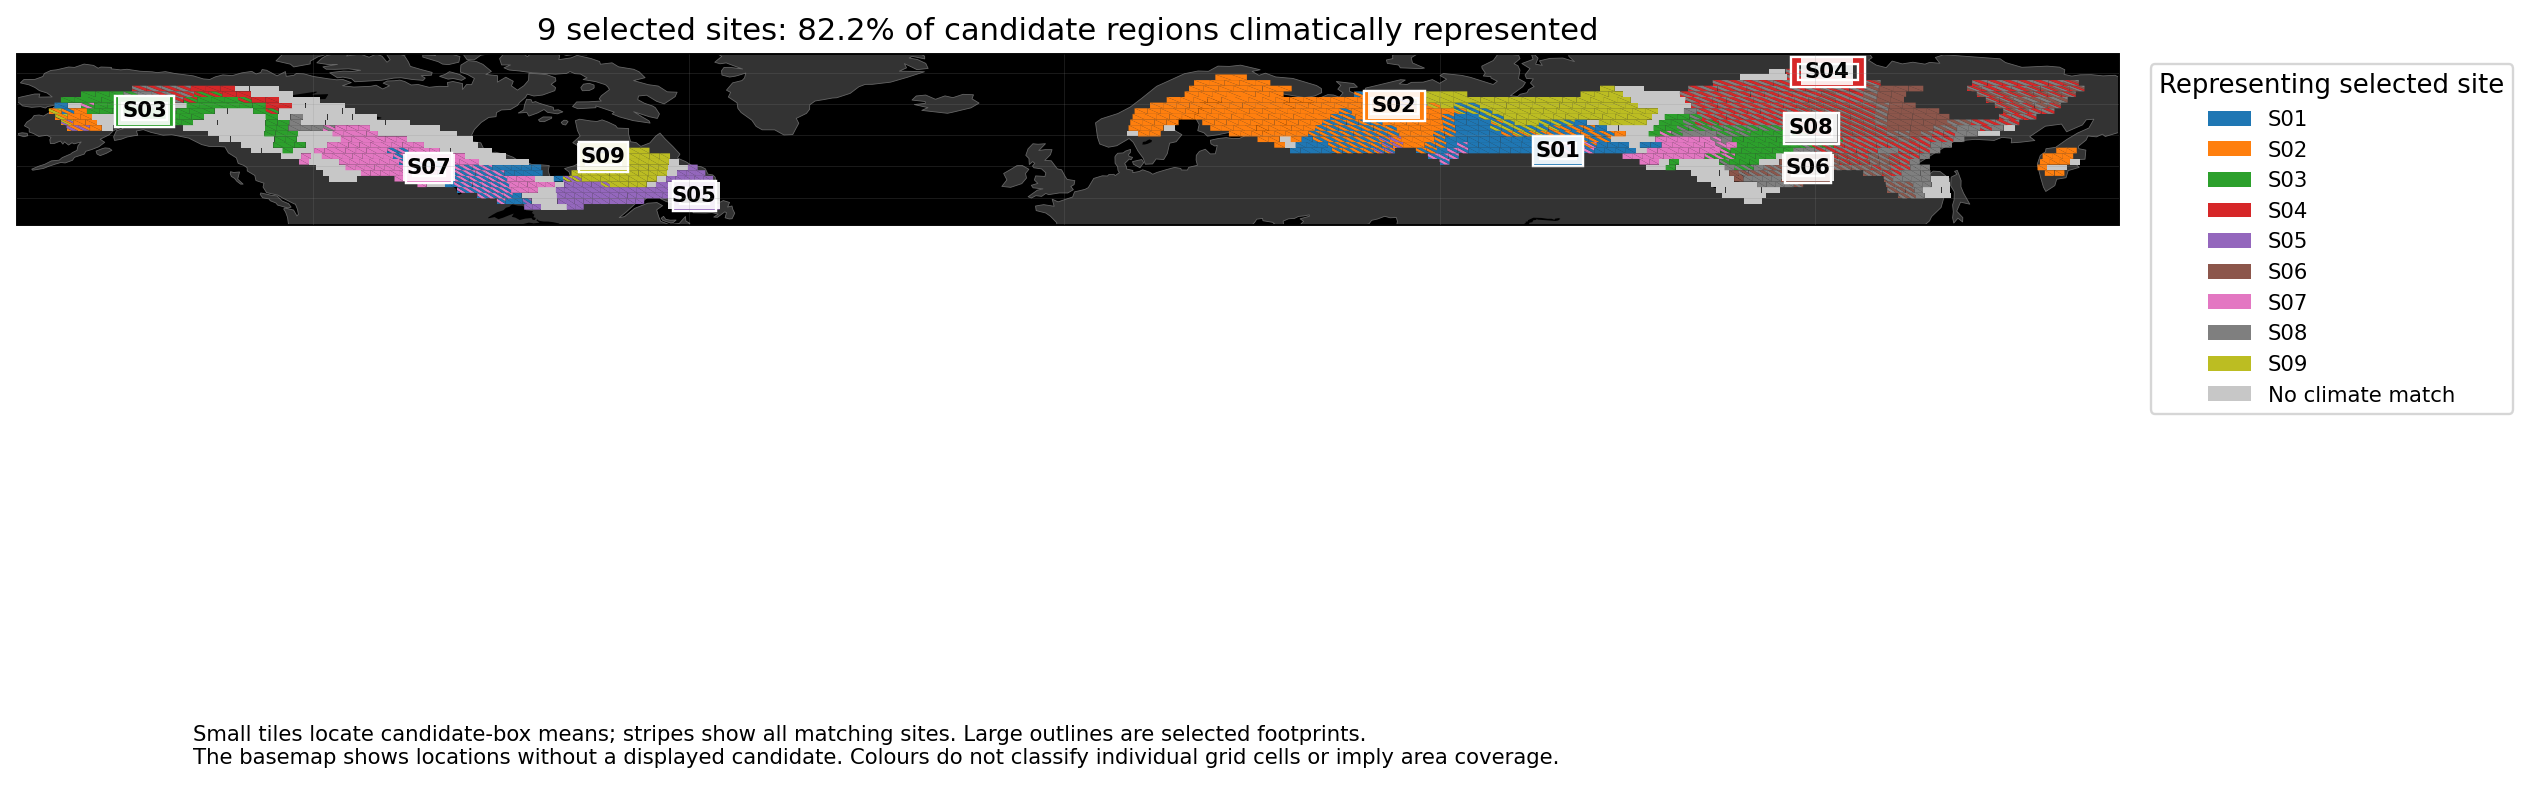

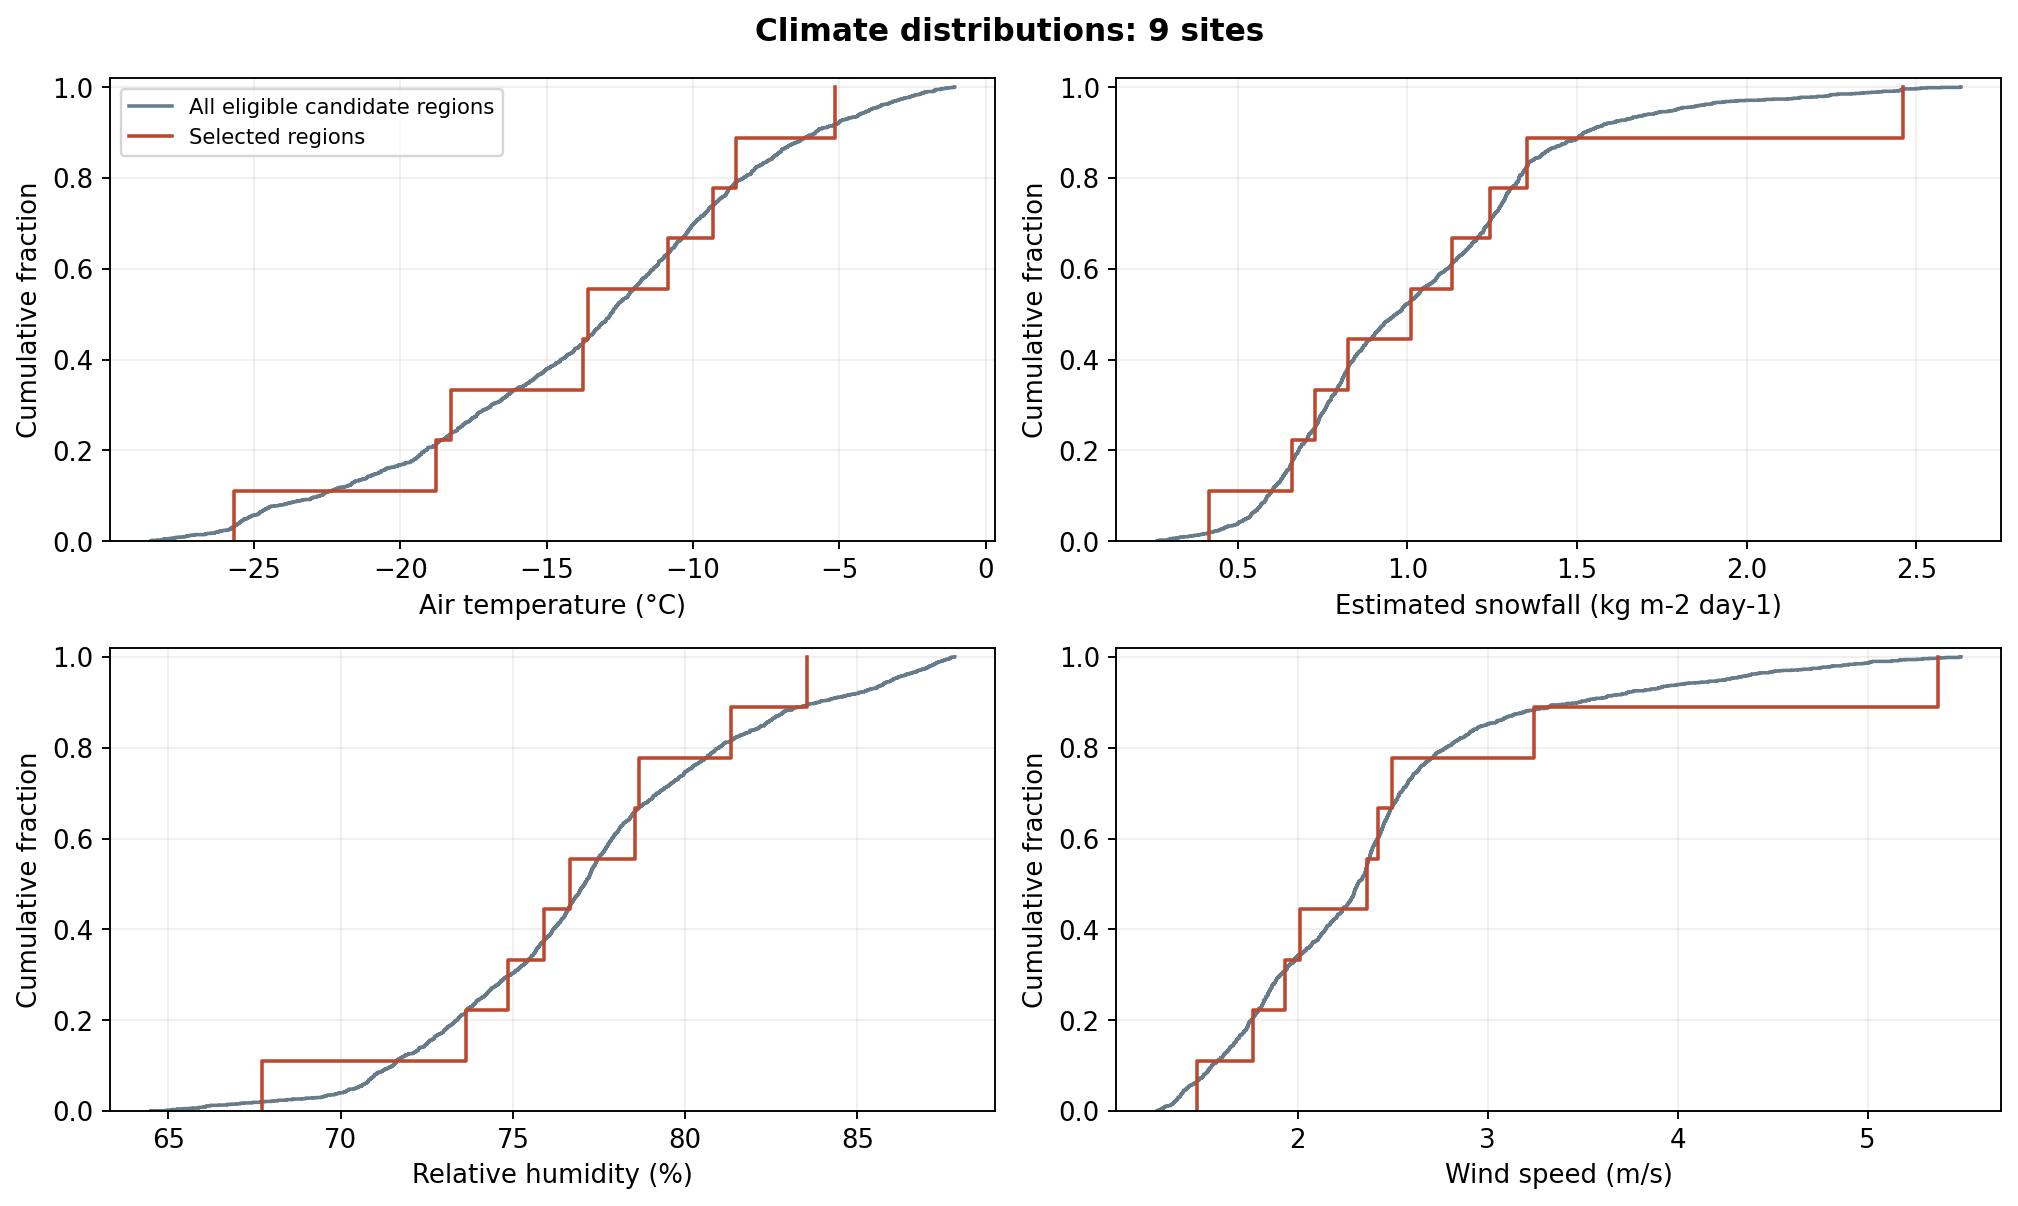

In [29]:
display(Image(filename=str(diagnostic_dir / f"n{SHOW_N:02d}_map.png")))
display(Image(filename=str(diagnostic_dir / f"n{SHOW_N:02d}_distributions.png")))


### Canopy contrasts and within-region climate spread

The error bars show regional means ± **spatial SD**, not uncertainty in the mean. Inspect these before treating each footprint as a single climatic regime.

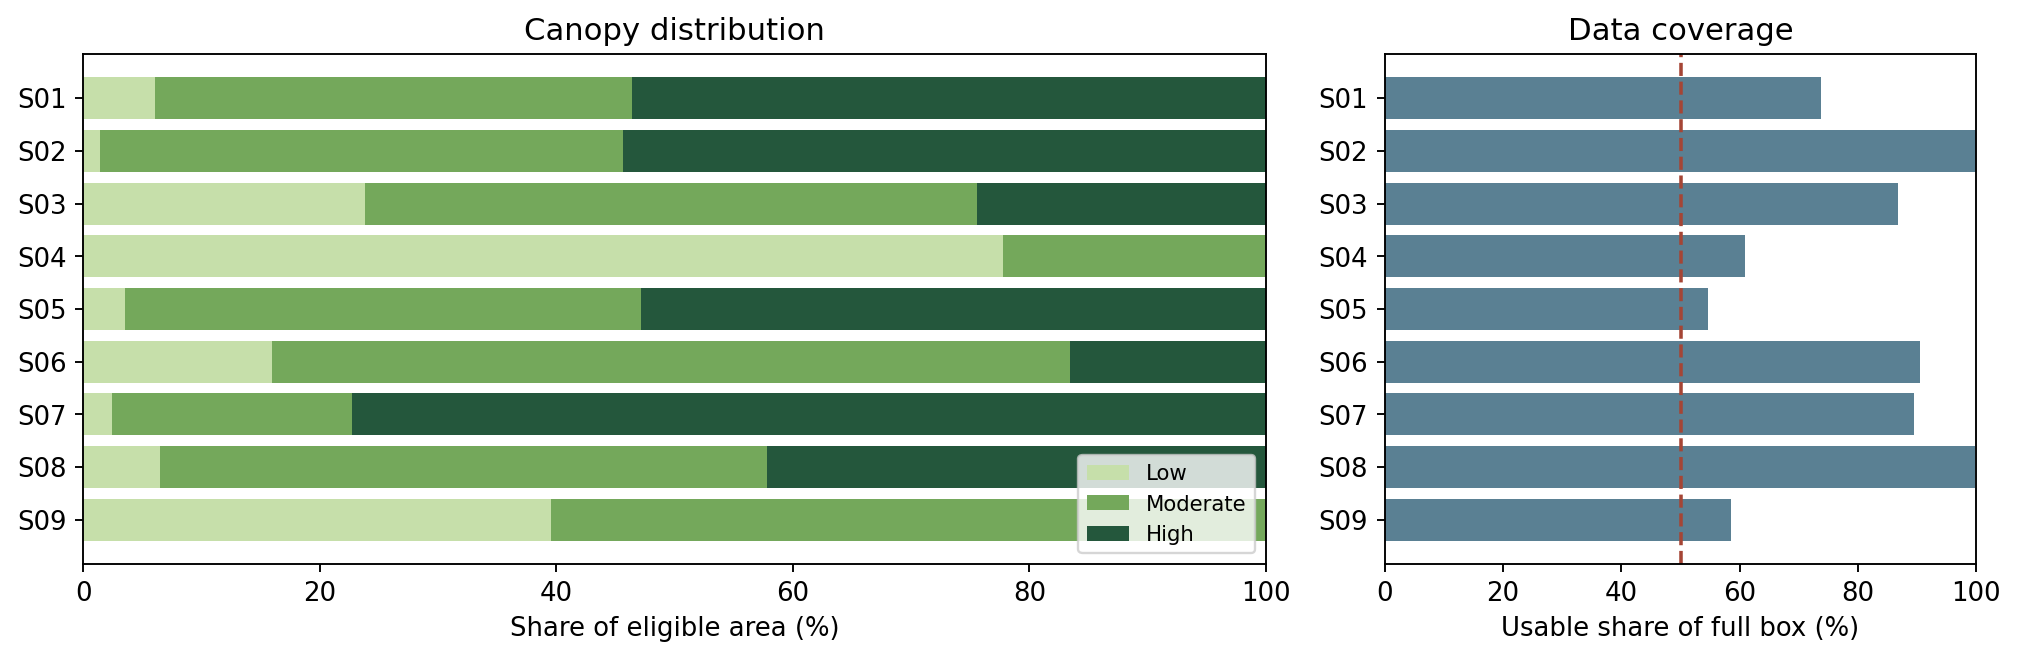

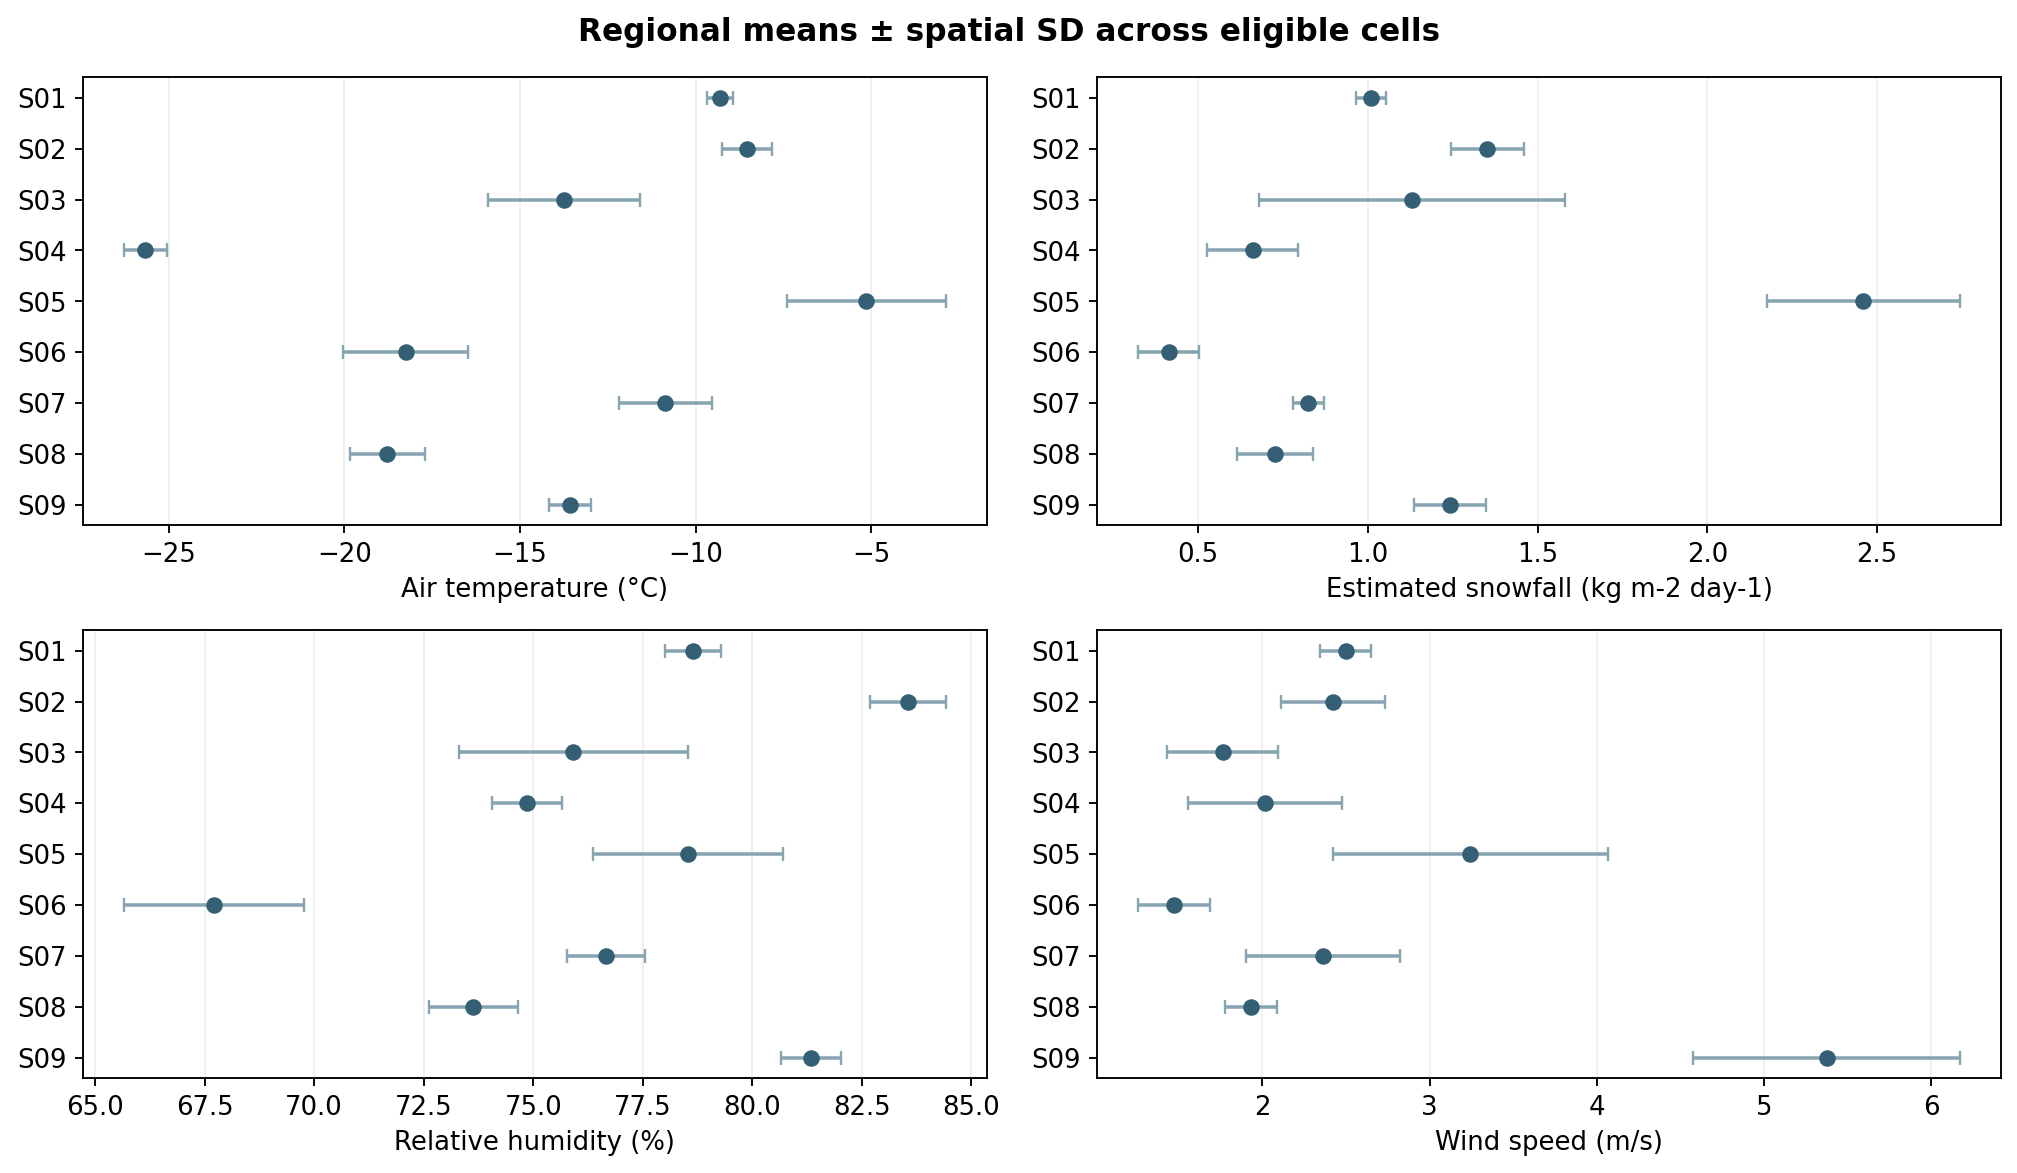

In [30]:
display(Image(filename=str(diagnostic_dir / f"n{SHOW_N:02d}_canopy_and_coverage.png")))
display(Image(filename=str(diagnostic_dir / f"n{SHOW_N:02d}_within_region_spread.png")))


### Pairwise climatic coverage

The percentile view makes differences among common conditions easier to inspect; the original-unit view shows their physical magnitudes.

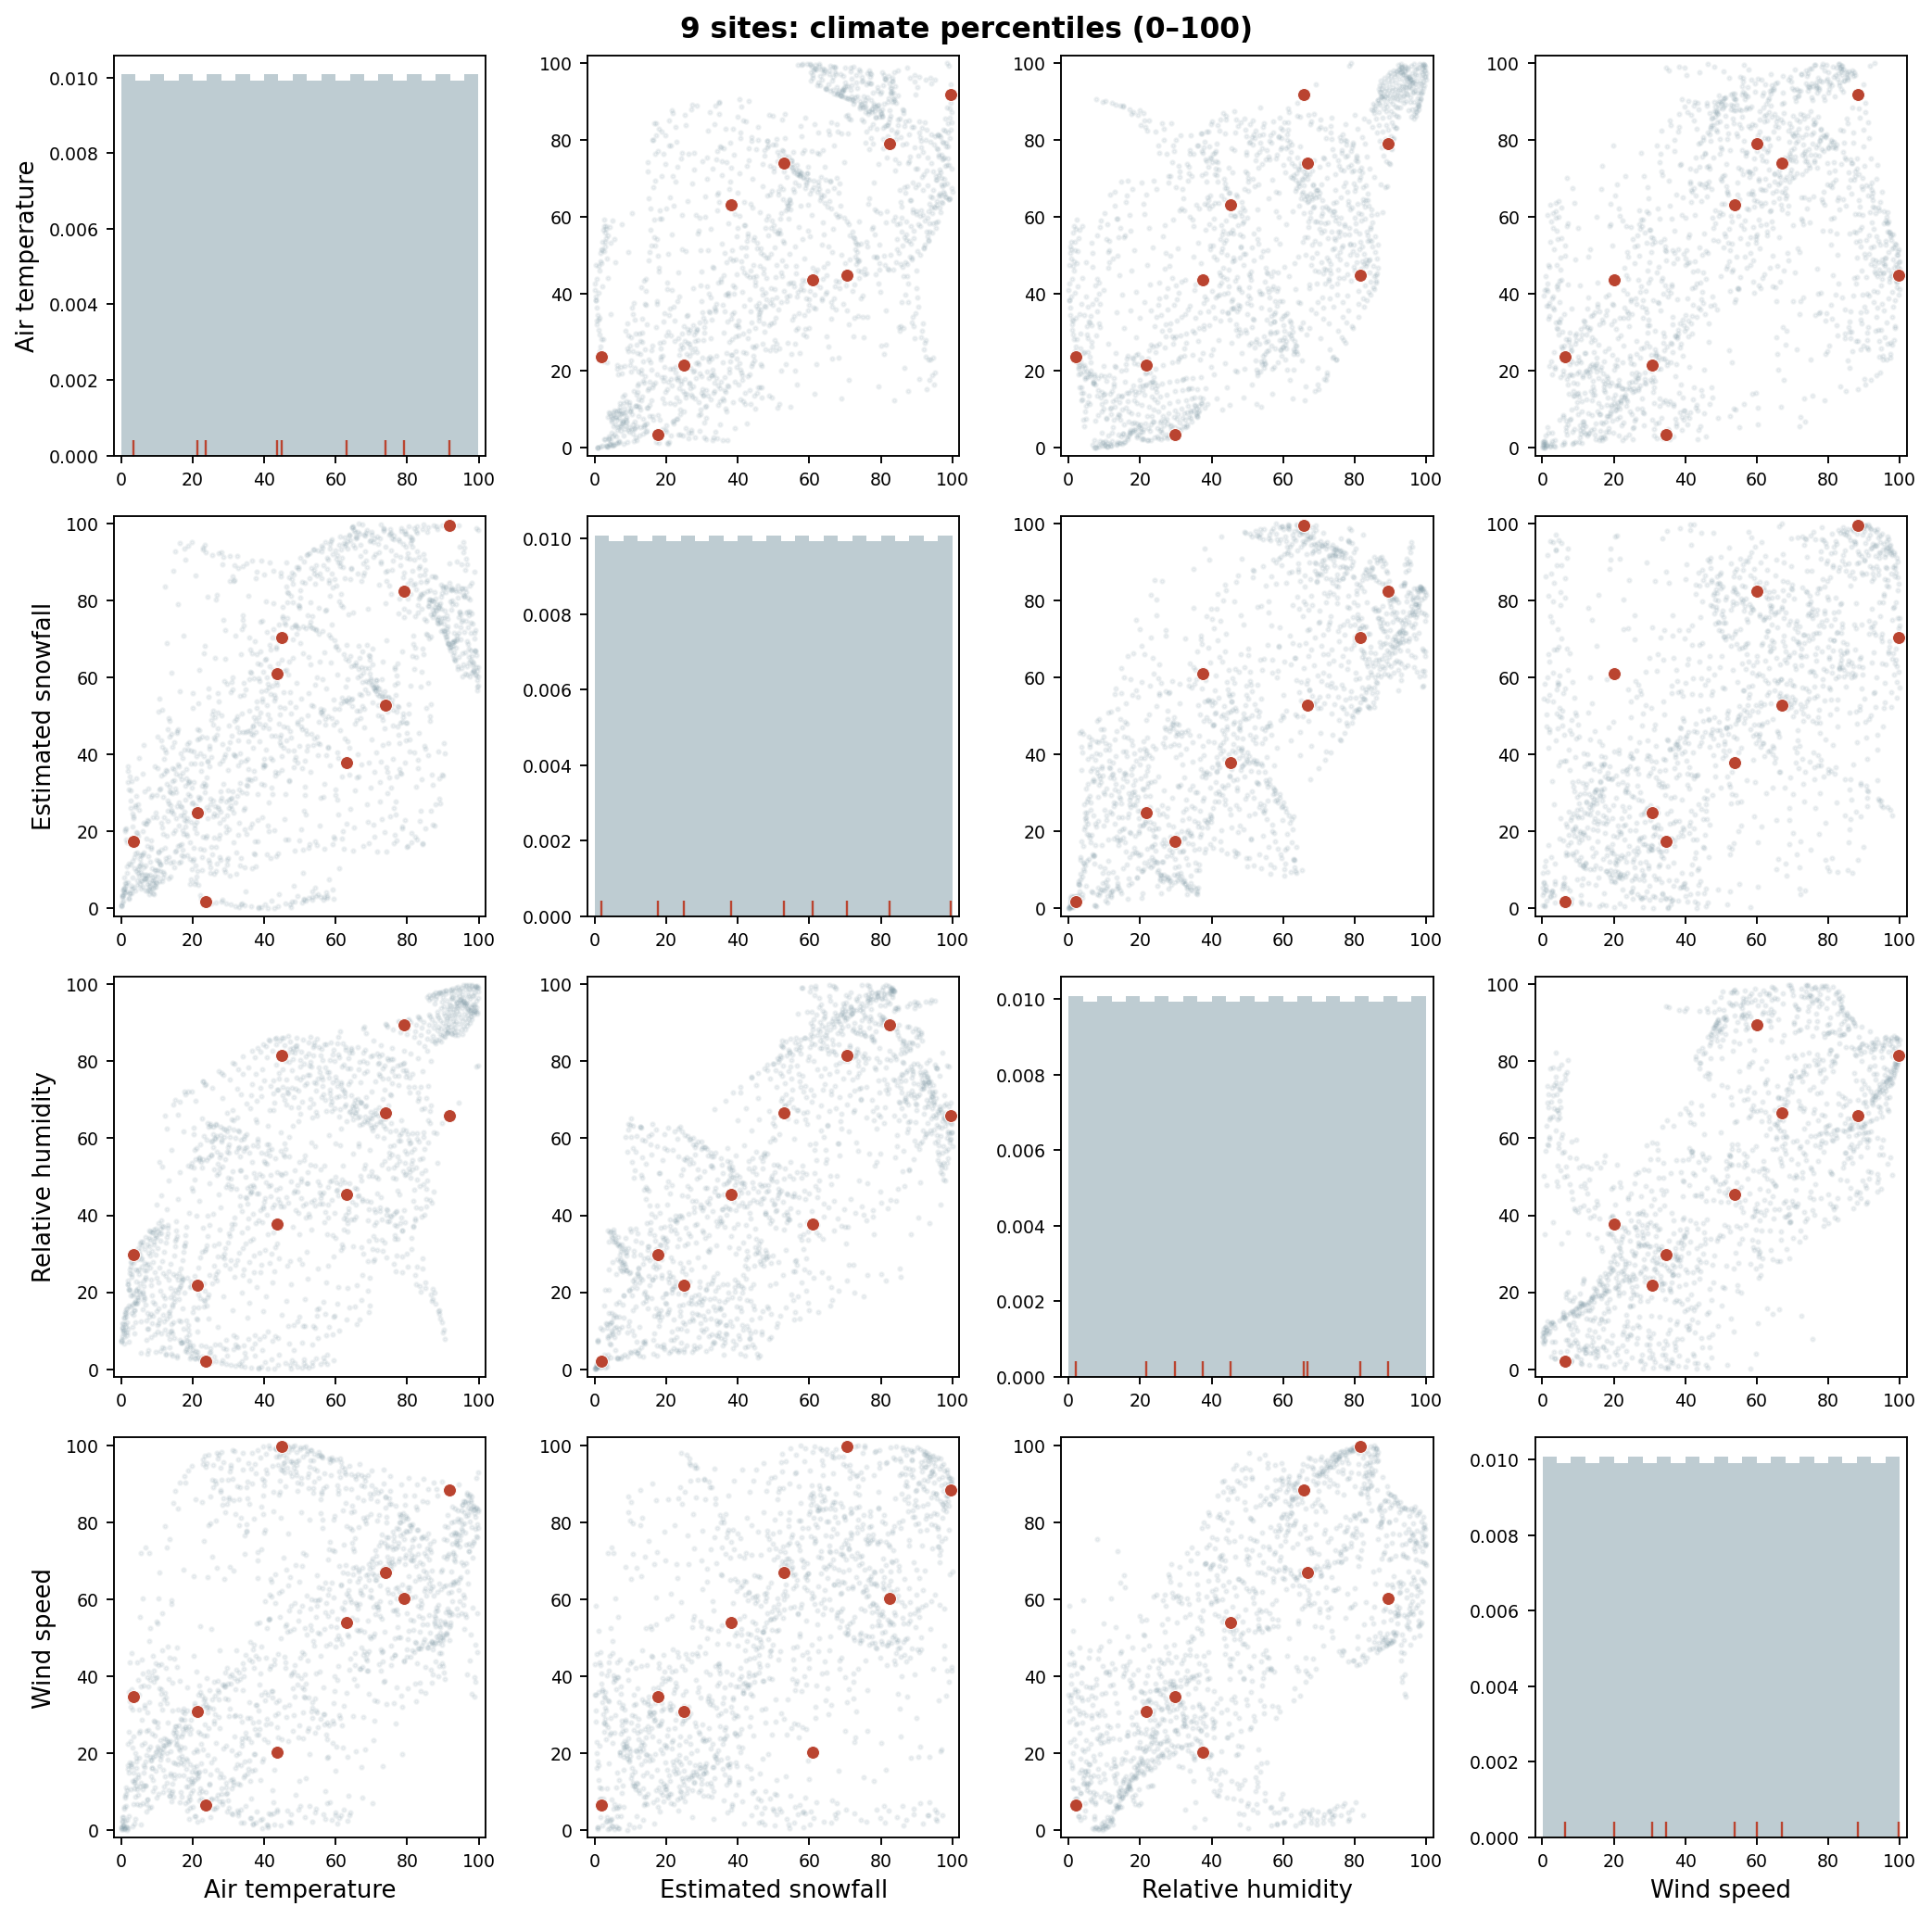

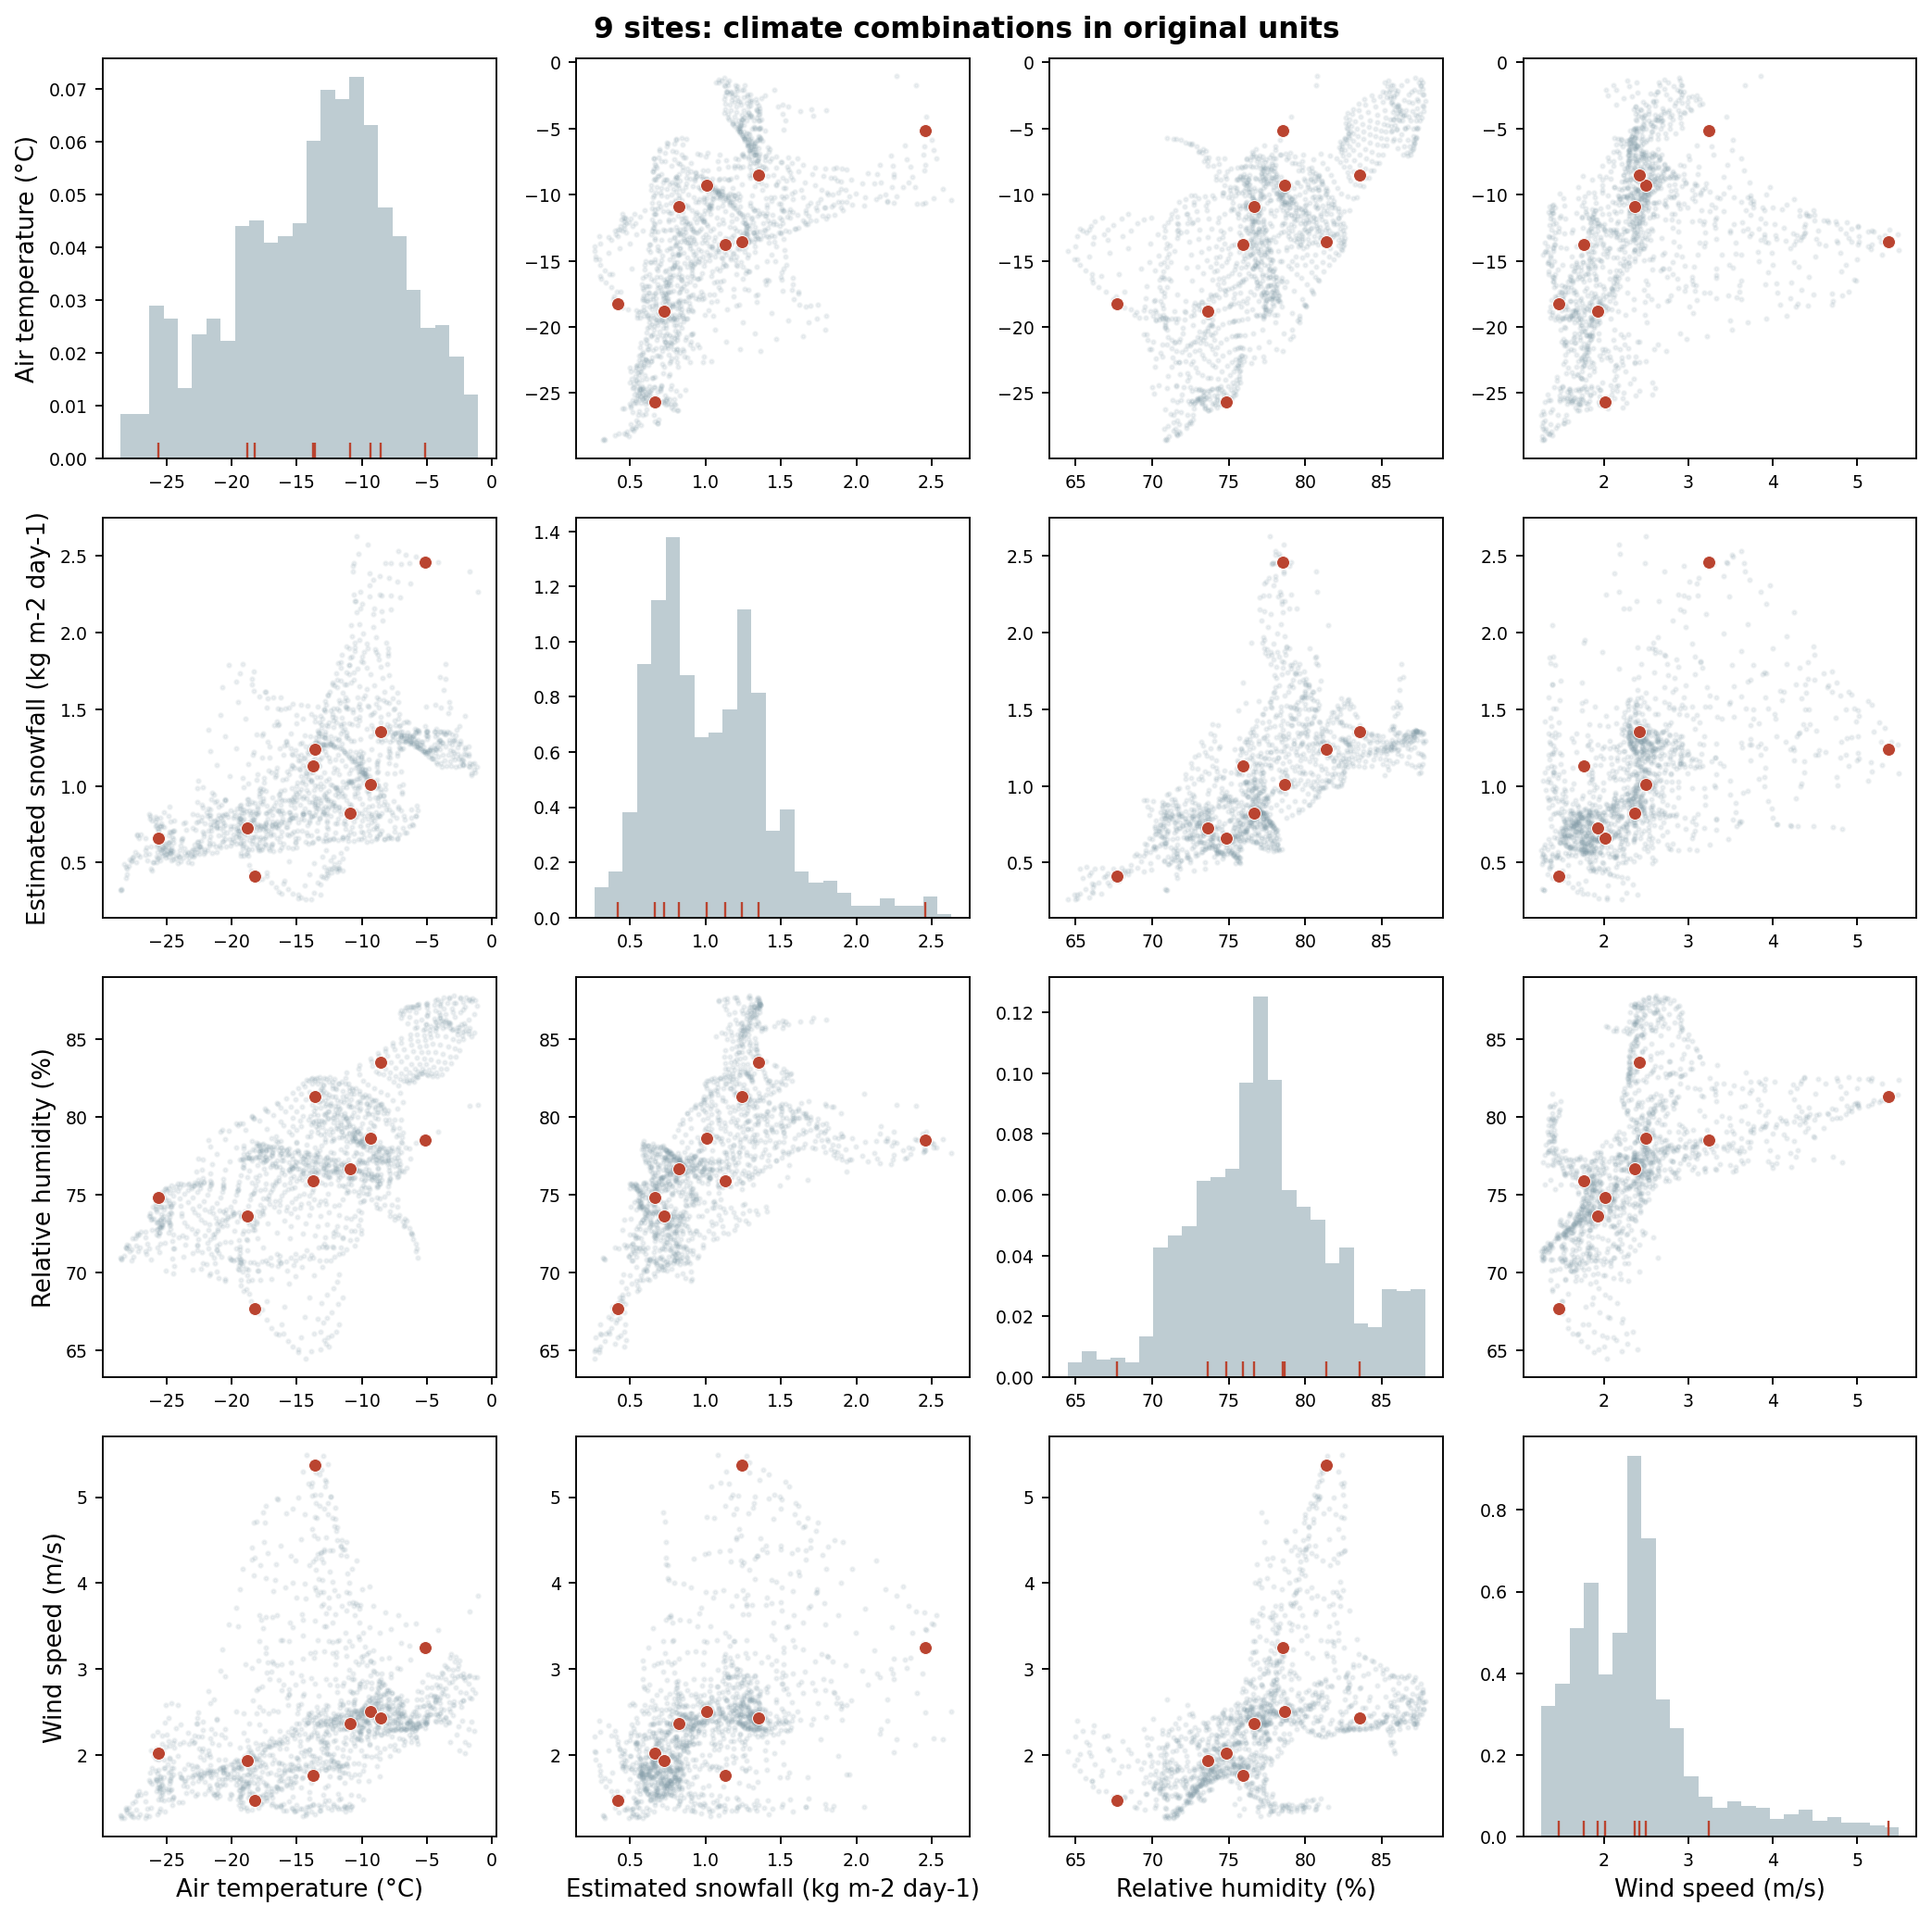

In [31]:
display(Image(filename=str(diagnostic_dir / f"n{SHOW_N:02d}_pairs_percentiles.png")))
display(Image(filename=str(diagnostic_dir / f"n{SHOW_N:02d}_pairs_units.png")))


### Daily variability, sample-size comparison and remaining canopy gaps

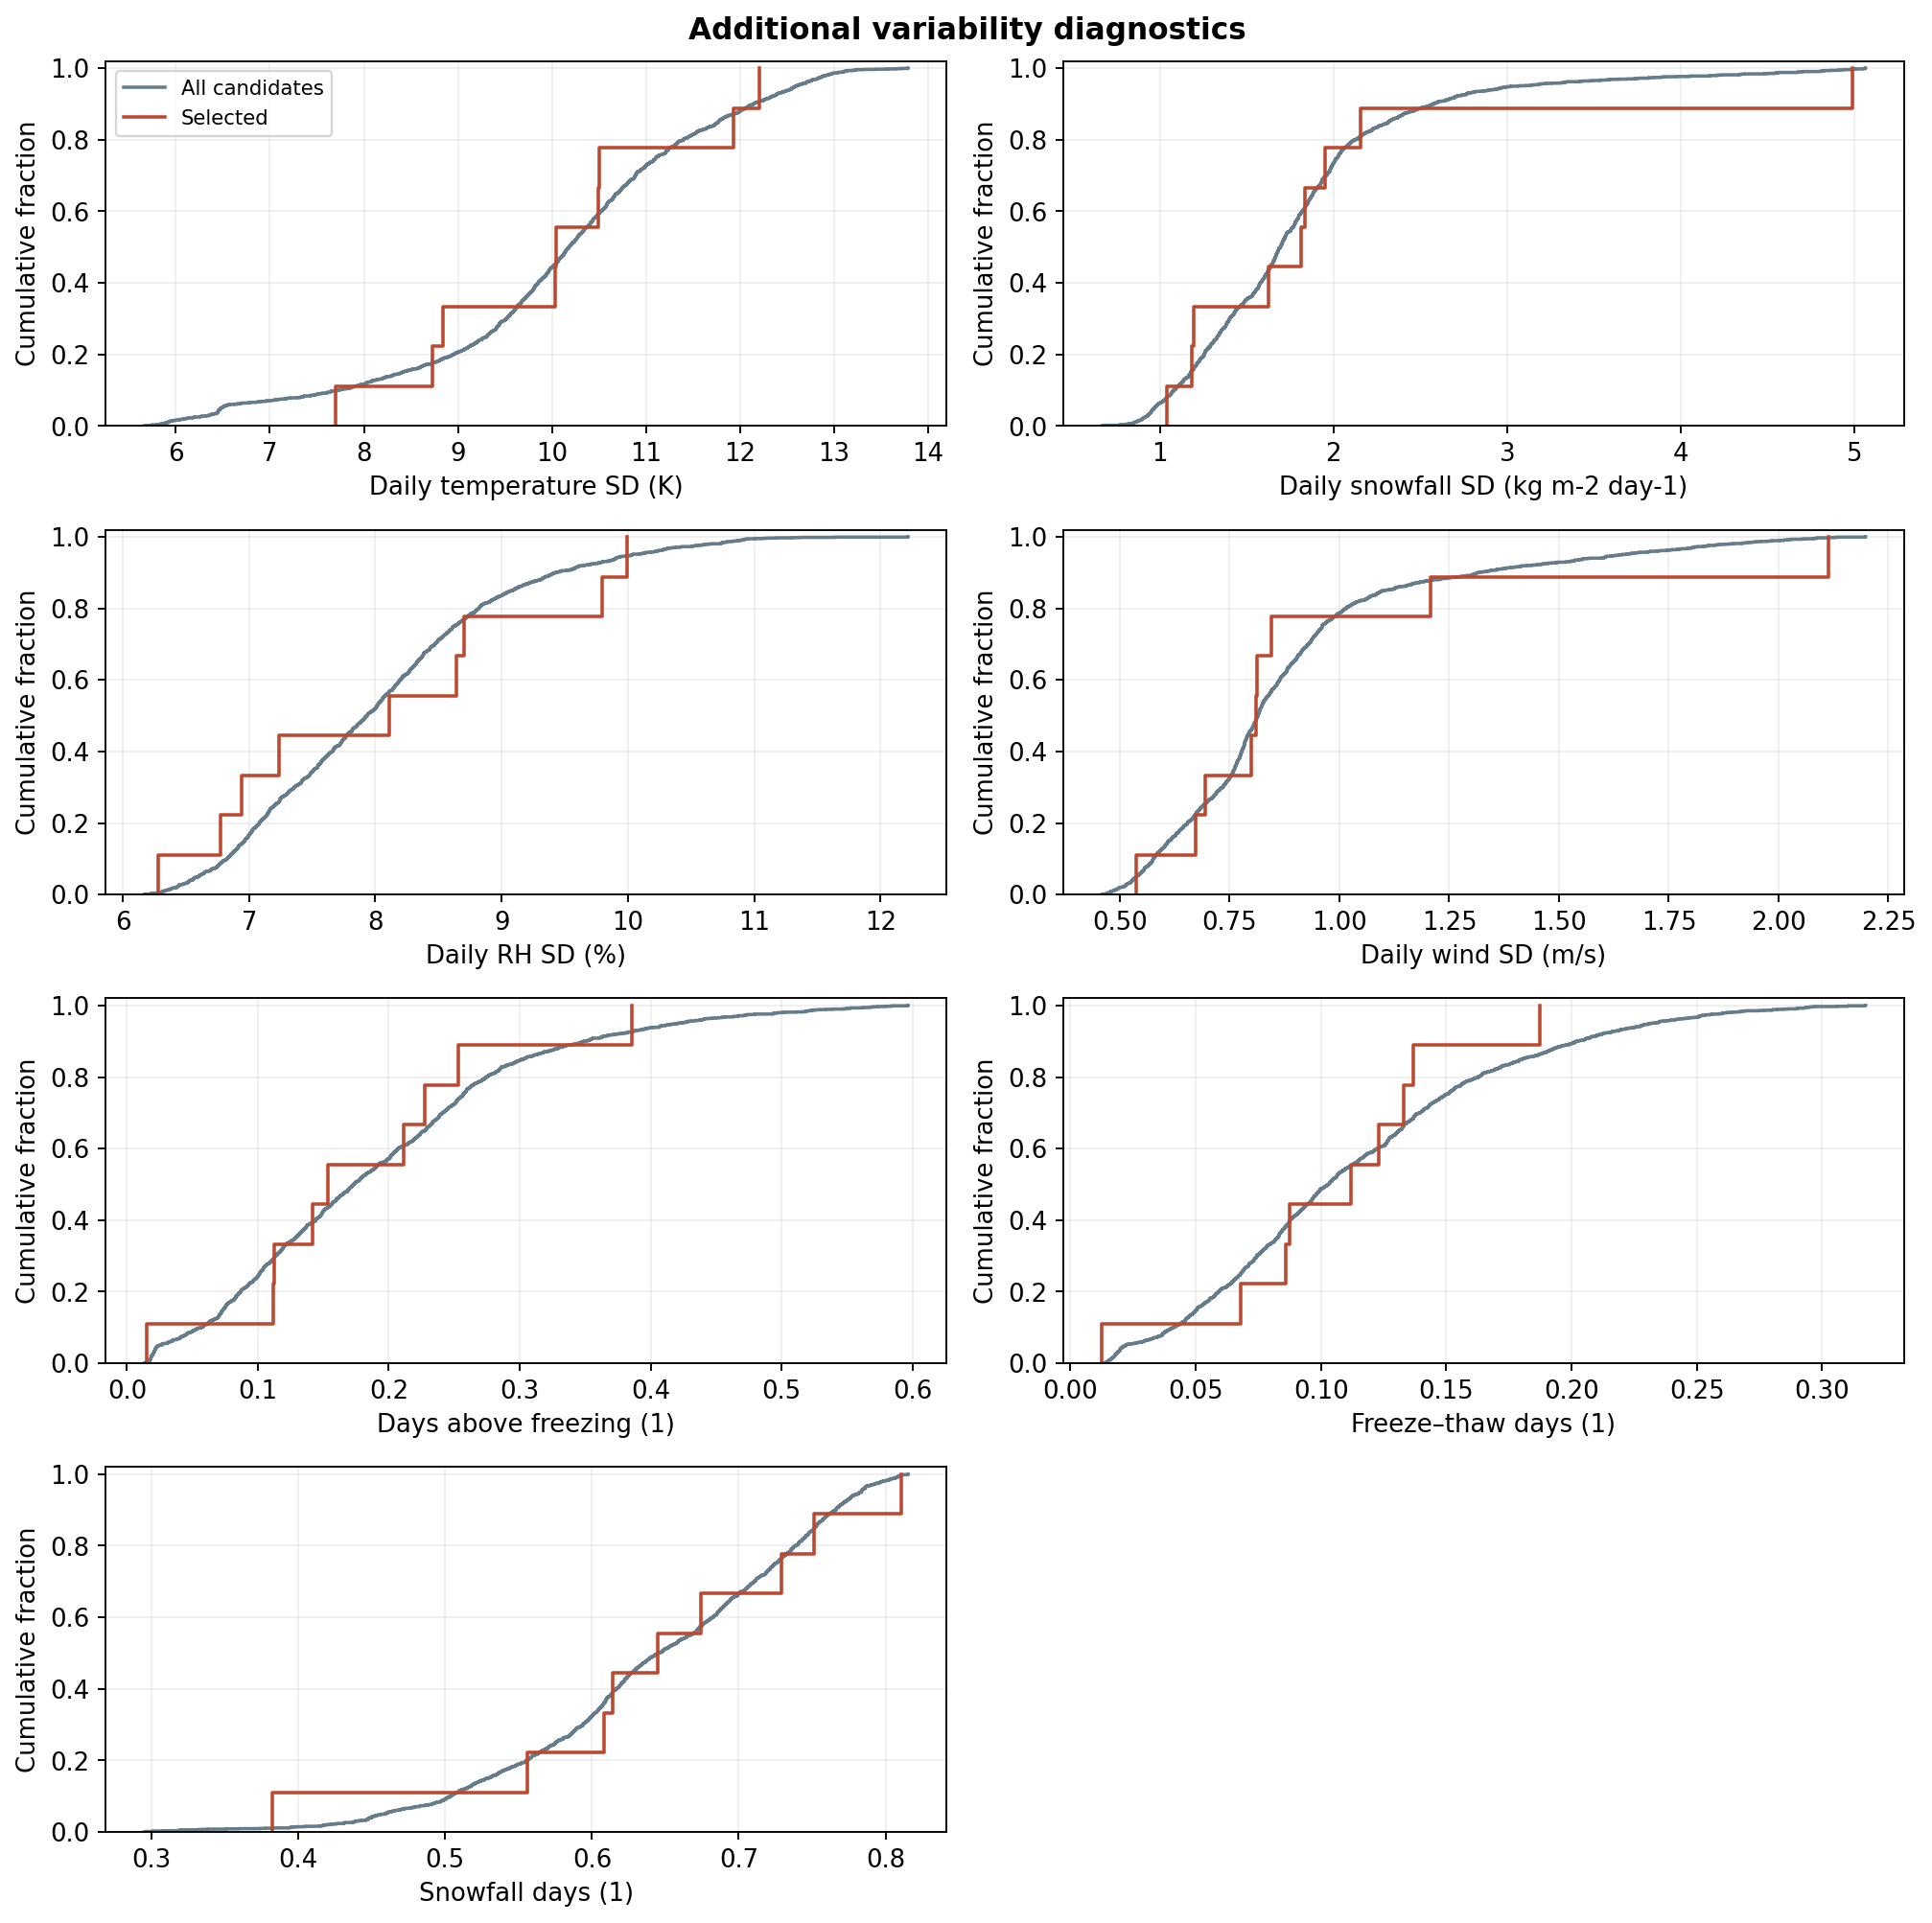

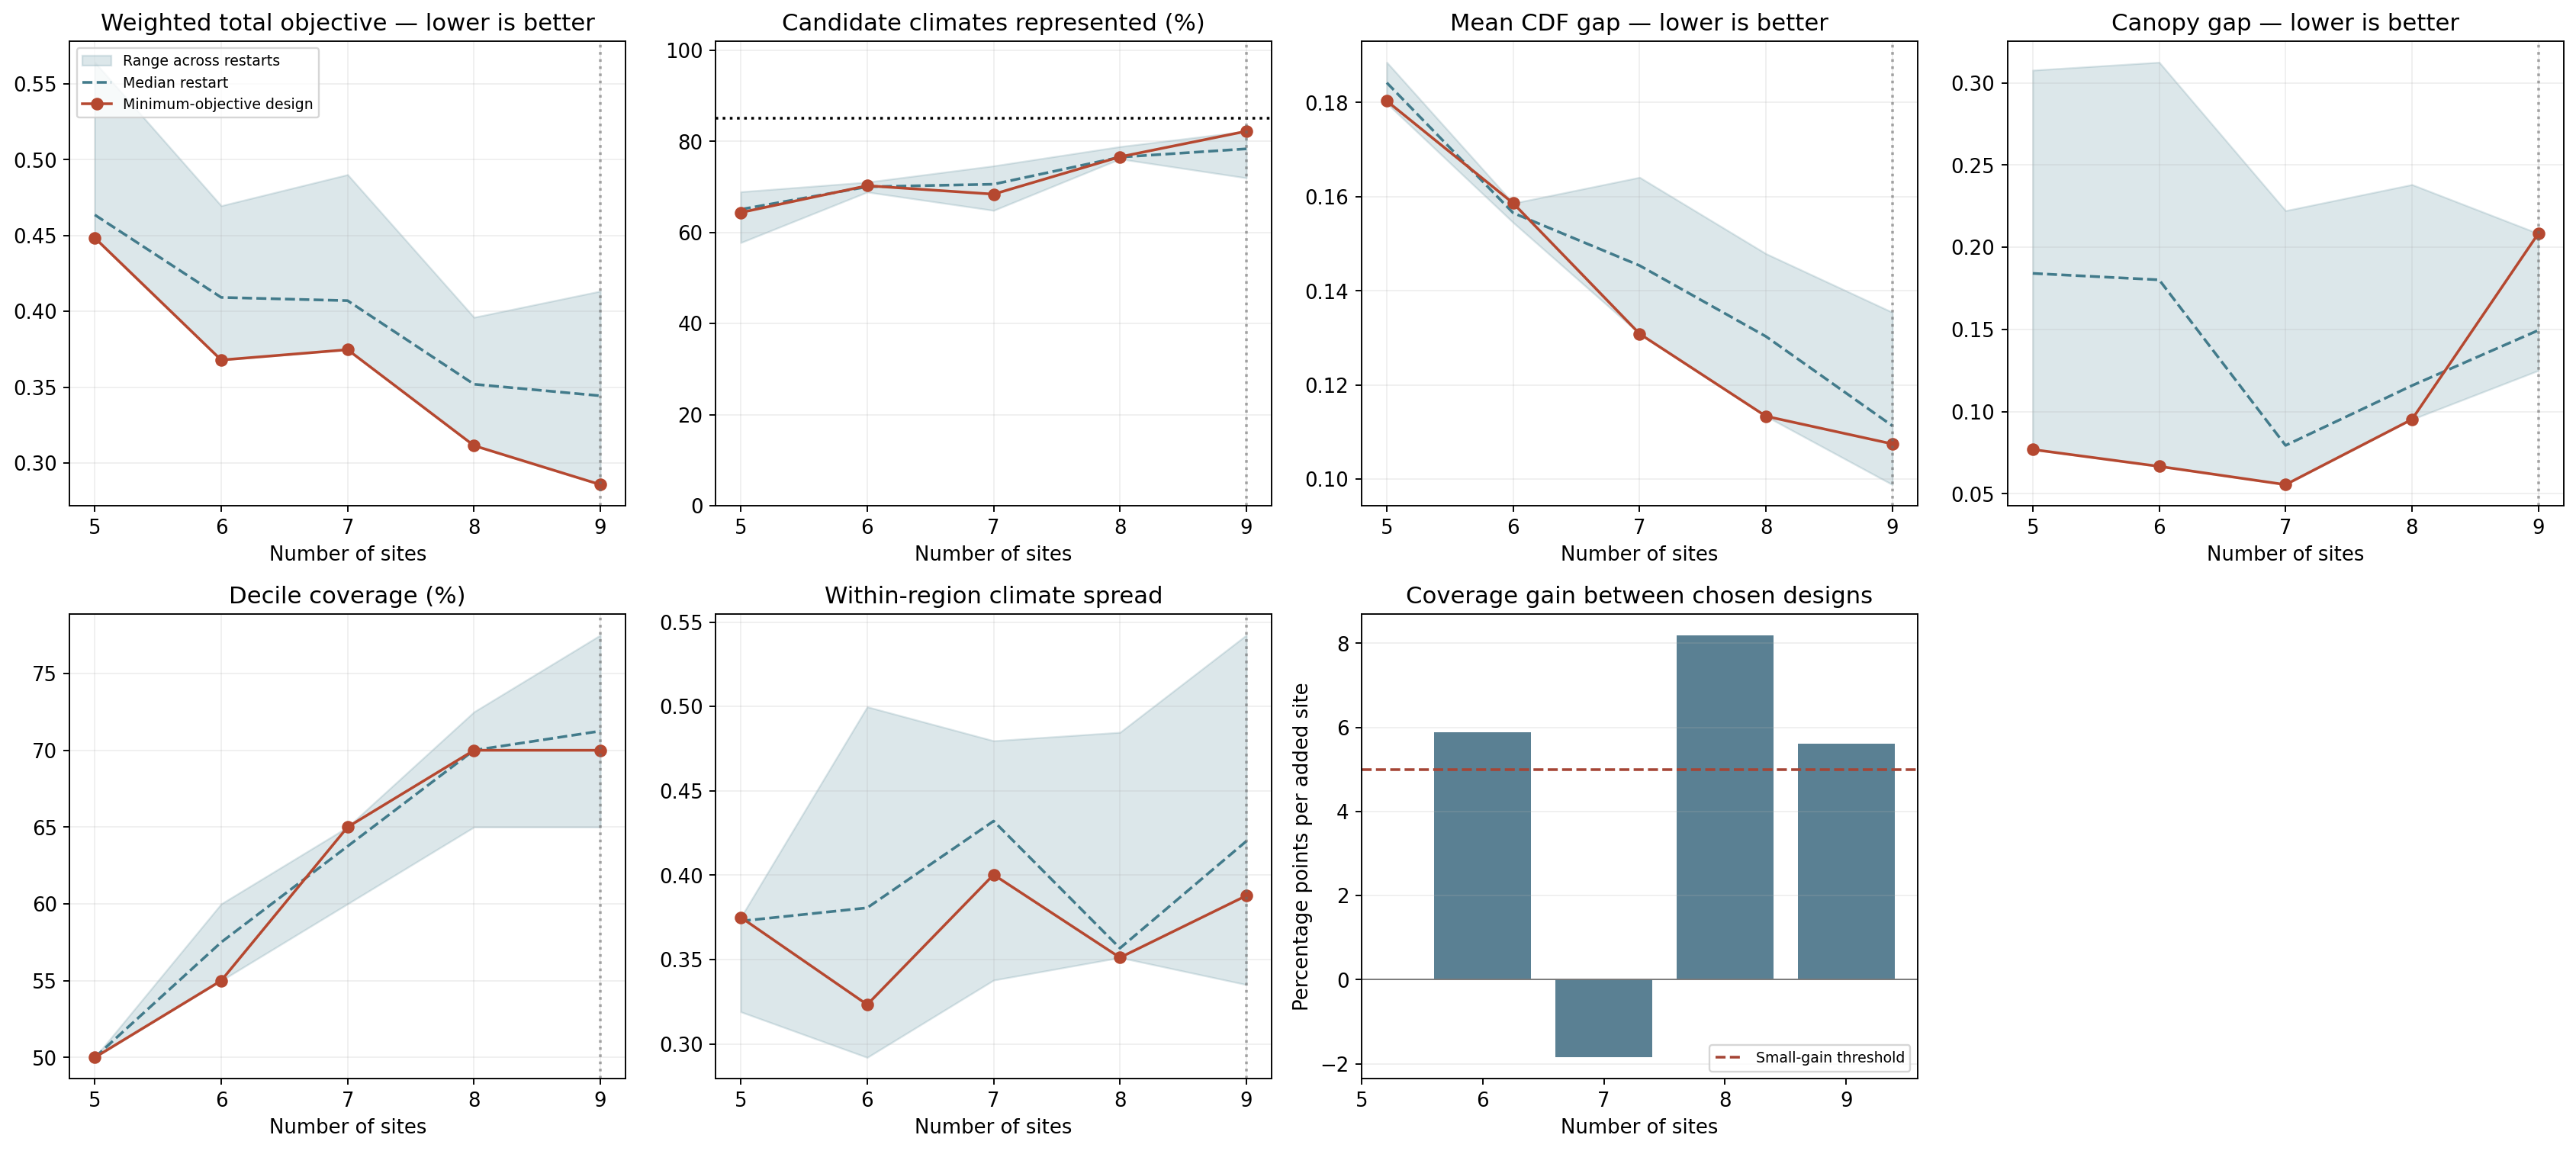

,variable,cdf_gap,occupied_deciles,attainable_deciles,decile_coverage,occupied_clhs_strata,attainable_clhs_strata,requested_strata,population_min,population_max,sample_min,sample_max
0,air_temperature_mean,0.106117,6,10,0.6,9,9,9,244.612455,272.098241,247.486132,268.006865
1,snowfall_mean,0.105824,9,10,0.9,9,9,9,0.260627,2.631528,0.414243,2.459638
2,relative_humidity_mean,0.110230,6,10,0.6,9,9,9,64.474579,87.825100,67.713536,83.541919
3,wind_speed_mean,0.107806,7,10,0.7,9,9,9,1.257823,5.491930,1.471339,5.373003


,site_id,low_missing_despite_candidates,moderate_missing_despite_candidates,high_missing_despite_candidates
0,S01,False,False,False
1,S02,True,False,False
2,S03,True,False,True
3,S04,False,False,False
4,S05,False,False,False
5,S06,True,False,False
6,S07,False,False,False
7,S08,False,False,False
8,S09,False,False,True


,anchor_site,candidate_id,additional_bands,max_climate_quantile_difference,west,south,east,north,note
0,S02,C002386,low,0.209518,153.1,53.0,159.4,56.7,Suggestion only; not added to the selected cou...
1,S02,C002809,low,0.216127,153.8,54.8,160.4,58.5,Suggestion only; not added to the selected cou...
2,S02,C002600,low,0.218771,153.4,53.9,159.9,57.6,Suggestion only; not added to the selected cou...
3,S03,C003247,high,0.134171,-127.1,57.5,-119.9,61.2,Suggestion only; not added to the selected cou...
4,S03,C002985,high,0.145406,105.6,55.7,112.4,59.4,Suggestion only; not added to the selected cou...
5,S03,C003246,high,0.157964,-128.8,57.5,-121.7,61.2,Suggestion only; not added to the selected cou...
6,S06,C003948,low,0.181097,138.1,60.2,145.9,63.9,Suggestion only; not added to the selected cou...
7,S06,C004615,low,0.181097,154.8,63.8,163.6,67.5,Suggestion only; not added to the selected cou...
8,S06,C004458,low,0.181758,153.9,62.9,162.4,66.6,Suggestion only; not added to the selected cou...
9,S09,C004092,high,0.119630,81.0,61.1,89.0,64.8,Suggestion only; not added to the selected cou...


In [32]:
variability_plot = diagnostic_dir / f"n{SHOW_N:02d}_variability_diagnostics.png"
if variability_plot.exists():
    display(Image(filename=str(variability_plot)))
display(Image(filename=str(diagnostic_dir / "sample_size_comparison.png")))

display(pd.read_csv(selection_dir / f"n{SHOW_N:02d}" / "distribution_metrics.csv"))
display(selected[["site_id"] + [band + "_missing_despite_candidates" for band in BANDS]])
display(pd.read_csv(selection_dir / f"n{SHOW_N:02d}" / "canopy_complement_suggestions.csv"))


## 8. Comparing another footprint size

Change `WIDTH_KM`, `HEIGHT_KM` and `CANDIDATE_SPACING_KM` in the settings cell, then rerun the three stage cells. For a 200 × 200 km experiment, a 50 km candidate spacing is a useful starting point. Previous results remain saved.

Alternatively, the optional cell below runs a separate experiment without altering the main settings. Each footprint size has a different candidate population, so CDF discrepancies between sizes are relative to different reference distributions.

In [ ]:
# Uncomment to run a separate 200 km experiment.
# import copy
# smaller = copy.deepcopy(current_config())
# smaller["candidates"].update(width_km=200, height_km=200, spacing_km=50)
# small_candidates = build_candidates(smaller)
# small_selection = select_sites(smaller, small_candidates)
# small_diagnostics = diagnose(smaller, small_candidates, small_selection)
